# Inkling-2-Mini on 1x CMP 170HX (SM80, 140 W) — Round 1–7 100% 0-ULP SM80 autoresearch megakernels, fused Humming SiTU epilogue, FlashInfer/rank-2 prefill, monolithic CUDA graphs & 13-group FP8 KV

| Metric (1 stock card, 140 W, 262,144 ctx) | Value |
|---|---|
| Decode, c=1 | **175.37 tok/s** median / **175.52 tok/s** peak (6-prompt panel, T=0.6; **169.56 tok/s** in 13-group FP8 KV) · **220.4 / 189.2 / 132.7 tok/s** code / structured / prose (**234.9** T=0 code, PR #90 suite) · **308.3–313.0 tok/s** JSON extraction |
| Best aggregate | **718.77 tok/s** peak (**718.77 tok/s** in 13-group FP8 KV · **703.09–705.96 tok/s** BF16 at c=16 on the same unified server; **657.42 tok/s** on PR #90 c=16 suite) |
| Prefill | **6,485 tok/s** at 4K · **6,788 tok/s** at 32K · **4,099 tok/s** at 131K · **3,584 tok/s** at 231K (`+36.0%` vs R6) |
| TTFT & Long KV | **0.092 s** short TTFT (**0.072 s** warm) · **216.41 / 169.38 tok/s** decode @ 131K / 231K (3/3 needles) · **805,704–809,126 KV tok (`3.07–3.09x` @ 262K, 13 KV groups, 110.3 s boot, 4×172.0K soak)** with `--kv-cache-dtype=fp8` |

![chart](../assets/charts/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm.png)

```
docker pull vllm/vllm-openai@sha256:c2dc759f5984f69c1e2418c6af7c26eb756f5ed2a8934c768ae1253645d1449e
```

Evidence: [results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/](../results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/README.md)

In [1]:
# --- Status cell -------------------------------------------------------
# LIVE = False replays the committed receipts under results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/receipts/.
# LIVE = True sends the final prompt cell to BENCH_ENDPOINT_URL (see Section 3).
import sys
from pathlib import Path
from IPython.display import Image, Markdown, display

LIVE = False
REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
RESULTS_DIR = REPO / "results" / "2026-11-22-inkling-2-mini-1card-sm80-opt-vllm"
sys.path.insert(0, str(RESULTS_DIR))
import summarize as S


def render_table(headers, rows):
    out = "| " + " | ".join(headers) + " |\n|" + "---|" * len(headers) + "\n"
    out += "\n".join("| " + " | ".join(str(c) for c in r) + " |" for r in rows)
    display(Markdown(out))


SB = S.scoreboard()
LEDGER = S.ledger_rows()
print("LIVE =", LIVE, "| receipts:", RESULTS_DIR.relative_to(REPO), "| milestone rounds:", len(SB), "| ledger runs:", len(LEDGER))

LIVE = False | receipts: results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm | milestone rounds: 8 | ledger runs: 136


## 1. TL;DR

**Verdict (measured):** Seven-round SM80 optimization follow-up to [PR #90 (`2026-11-21-inkling-2-mini-1card-vllm-sm80-dspark-vs-llamacpp`)](2026-11-21-inkling-2-mini-1card-vllm-sm80-dspark-vs-llamacpp.ipynb) on a **stock CMP 170HX 64 GiB @ 140 W TDP, 1,140 MHz SM / 1,728 MHz HBM2e, 1,600.5 GB/s D2D copy BW** at full **`262,144`-token context** (strict `140.00 W` TDP cap, `0` register spills, `100% 0-ULP` lossless target decode distribution) lifts single-user 6-prompt median decode **`108.6 → 135.0 → 155.5 → 164.2 → 167.2 → 171.8 → 173.8 → 175.37 tok/s` (`175.52 tok/s` peak, `+61.5%` / `+61.7%` over baseline, beating all 4 bracketed Round-6 controls AND Round-6 Best on 6/6 prompts simultaneously)** and unified-server `c=16` aggregate throughput **`491.1 → 521.9 → 604.2 → 669.5 → 676.0 → 710.2 → 710.9 → 703.1 tok/s` (`718.77 tok/s` peak, `+46.4%` — all-time `c=16` record in 13-group FP8 KV)**, while jumping cold prefill to **`6,484.9 / 6,787.6 tok/s`** (`~4K` / `~32K`, `+14.7%` at `32K` over Round 6) and cutting startup from **`432.5 s` to `110.3–112.3 s`**. Cross-validated on a 108-SM **A100-SXM4-40GB** (`sm_80`, `131K` 13-group FP8 KV), our SM80 stack lifts end-to-end `vllm serve` `c=1` decode **`169.17 → 187.09 tok/s` (`+10.6%`)** and `c=16` **`1,116.96 → 1,189.20 tok/s` (`+6.5%`)**.

- **Apples-to-apples on PR #90's harness at `262,144` context (`receipts/pr90-r7best.jsonl`):** `220.4 tok/s` code (**`234.9 tok/s` at `T=0`**, `235.3` peak), `189.2 tok/s` structured JSON (`189.8` `T=1` median, `226.5` peak), `132.7 tok/s` prose (`135.9` peak), and `657.4 tok/s` at `c=16` — beating PR #90's stock-card baseline (`146.0 / 136.8 / 87.5`) by **`+38%` to `+52%`** and PR #90's `+200 MHz SM offset` card at `32K` context (`166.9 / 189.1 / 94.0` at `T=0`, `510.9` at `c=16`) by **`+40.8%` code (`T=0`), `+41.2%` prose, and `+28.7%` (`+46.4%` unified peak) at `c=16`**. On the 768-token agentic suite (`receipts/agentic-r7-0ulp-bf16.json`), Round 7 reaches **`241.9 tok/s` `T=0.6` mean (`308.3 tok/s` JSON extraction peak, `239.1 tok/s` code refactor peak — `+5.3%` over Round 6)**.
- **Lossless target decode distribution, 262K long-context & 13-group coalesced `--kv-cache-dtype=fp8` `3.07–3.09x` mode (`receipts/r7-gates-summary.json`, `receipts/soak-4x173k-r7-fp8kv.json`):** BF16-KV long-context needle retrieval is **`3/3` at `131,227` tokens** (**`4,098.9 tok/s` prefill `+12.0%` vs R6, `216.41 tok/s` decode**) and **`3/3` at `231,044` tokens** (**`3,584.3 tok/s` prefill `+36.0%` vs R6, `169.38 tok/s` decode `+5.5%` vs R6** — all-time `231K` records); **`2/2` concurrent `167.8K`-token soak** (`335,655` KV tok in **`86.4–87.6 s`, `-22.7%` faster** than Round 6) and **GSM8K-50 `49/50 (98.0%)`** (`50/50` in Round 6). In 13-group coalesced `--kv-cache-dtype=fp8` (`805,704–809,126` KV tok = `3.07–3.09x` @ `262,144`), Round 7 (`cand-58`) lifts FP8 `c=1` short decode **`121.62 → 162.59 → 167.66 → 169.56 tok/s` (`169.71` peak, `+39.5%` over R4 FP8, beating R6 FP8 on `6/6` prompts simultaneously)**, sets the all-time **`c=16` record at `718.77 tok/s` (`+46.4%`)**, cuts startup to **`110.3 s`**, lifts `131K / 231K` FP8 decode to **`204.32 / 152.80 tok/s` (`3/3` needles)**, and passes **`4 × 172.0K` concurrent soak (`4/4` streams = `689,932` KV tok in `409.6 s`, `12/12` needles)** + **GSM8K-50 `48/50 (96.0%)`**.
- **Eight verified pillars across Waves 0–15 (`receipts/ledger.jsonl`):**
  1. **Round-7 `100% 0-ULP` fused Humming SiTU epilogue, pass-hoisted/rank-2 loop bank, FlashInfer/Triton hybrid prefill, 5-way `qkv_dyn` & TP=2 (`humming_include/humming/epilogue/gmem_writer.cuh`, `sm80_r6_ext.cu`, `nvidia/loop.py`, `nvidia/ops/{attention_sm90.py,moe_sm90.py,ll_gemm_sm80.py,conv_mix.py}`, `sm80_tp_ops.py`, 0 spills):** fuses softcapped SwiGLU (`gate_cap=4.0, up_cap=25.0`) + routing `gamma` inside Humming's `w13` epilogue (`-48` launches/step, `3×` less `w13 → w2` HBM traffic at `0-ULP`), hoists all 48 core queries per pass in `_bank_attn_res_1pass_kernel` (`-22` launches/step at `0-ULP`), decomposes `T >= 256` prefill bank attention via zero-spill CUDA MMA rank-2 kernels (`-44.0%` loop prefill, `-450 MB` peak VRAM), accelerates `T > 64` `combine_conv` (`-62.4%`) + `BM=32/128` prefill MoE buckets (`-20.5%`), routes `max_query_len >= 256` global prefill to zero-copy FlashInfer HND `FAR` + Triton `NEAR` (`-47.7%`) and local prefill to 3-interval unmasked Triton (`-32.8%`), adds `0-ULP` `FAR` decode attention (`-6.7%`) and 5-way single-loop `_qkv_dyn_bmm_kernel` (`-28.6%`, `-16` launches/step), and registers `_C::vocab_parallel_embedding` for `TP=2`.
  2. **Round-6 `100% 0-ULP` SM80 autoresearch CUDA & Triton kernels (`patches/sm80_r6_ext.cu` → `libsm80_r6_ext.so`, `nvidia/loop.py`, `nvidia/dspark.py`, `speculator.py`, 0 spills):** 1-launch 48-CTA (`BN=8 × 3` exact K-groups `1024, 1024, 256`) double-buffered MMA `select_and_align_mma256_k3g_t16` (`maxdiff = 0`, `-96` launches/step), `combine_2304_r6` + `cp.async` `conv_mix_288_r6` (`0-ULP` fused `combine_conv_mix_2304`), `0-ULP` `sm80_up_blend_x_mma_2304` + `sm80_rms_norm_x_2304`, preallocated `_partials_workspace` (`-48` allocs/step) + `156 KiB` GA100 SMEM cap in `ll_gemm_sm80.py`, and `0-ULP` `sm80_mix_rmsnorm_4x` + 4-warp `_qk_norm_rope_write_kv_kernel` + `_dspark_embed_block_kernel` + batched `c=16` `sm80_markov_sample_batch` (`-52.9%` DSpark `c=16` latency).
  3. **Universal `0-ULP` (`torch.equal == True`) 140 W Cold-HBM SM80 Humming v5 MoE buckets (`nvidia/ops/moe_sm90.py`):** `cta=3` `[8, 128, 64] stg=5` on `NVFP4 w13 (16, 256]` (`-0.461 ms/step`), `cta=3` `[8, 128, 128] stg=3` on `NVFP4 w2 (16, 256]`, `cta=2` `[8, 256, 128] stg=4` on `NVFP4 w13 (256, 912]` (critical for `718.77 tok/s` uniform `c=16` routing), `stg=4 cta=3` on `MXFP8 w2` (`1.553 → 0.863 ms`), and dynamic `num_compute_units()` across 74-SM CMP 170HX and 108-SM A100.
  4. **Standalone SM80 CUDA megakernels (`patches/sm80_fast_v6.cu` → `libsm80_fast_v6.so`, 0 spills):** `moe_align_v3_sm80`, `select_and_align_32cta_128_sm80`, `<1 KB`-smem `conv_mix_2304_sm80`, `pair/blend_rms_norm_2304_sm80`, `markov_rnn_gate_256_sm80`, and 1-launch bitwise-exact `markov_fold_gumbel_cache_r1_sm80`.
  5. **SM80 low-M Tensor-Core linears & FA2 vision (`nvidia/ops/ll_gemm_sm80.py`, `nvidia/model.py`, `nvidia/vision.py`):** ported & tuned `_ll_gemm_kernel` and 1-launch `_qkv_bmm_kernel` (`vllm` PR `#69168`), `BN=128` (`68` CTAs on 74 SMs, `44.0 µs` 4-stage) on `8600×2304` `loc_qkvr`, batched `MP=64` `_ll_gemm` for `loop.blend`, `cuBLAS` `M >= 5` `lm_head`, and SM80 FA2 23-layer ViT vision.
  6. **Lossless DSpark `K=49,152` pruning + zero-scatter `-inf` `DraftLogitsCache` + bidirectional `k=4` + joint block verification (`"block"`) + dynamic batch `k` (`[[1,2,4],[3,6,3],[7,256,2]]`):** `fold_weight` shrinks `102.9 → 25.17 MB` to fit inside the CMP 170HX's `32.0 MiB` physical L2 cache; joint block verification lifts prose decode `+13.3%`; dynamic `k` unifies `c=1` (`k=4`) and `c=16` (`k=2`) in one server.
  7. **Monolithic `M <= 21` FULL CUDA graphs + slots-safe Sconv metadata deduplication + 18-split SM80 global decode attention (`nvidia/attention.py`, `nvidia/ops/attention.py`):** eliminates 48 piecewise graph breaks/step, deduplicates `sconv_seq_metadata` (`6 → 1` launch/step), and reaches `1,329.8 GB/s` (`89.1%` raw HBM2e peak) at `131K` (`216.4–219.2 tok/s` decode).
  8. **13-group coalesced unit-scale SM80 E4M3 FP8 KV (`nvidia/dspark.py`, `nvidia/ops/attention.py`, `nvidia/ops/sconv.py`):** branchless 9-instruction SIMD PTX `e4m3x2 → f16x2` + IEEE RNE `_fp32_to_e4m3fn_u8` across Target and DSpark coalesce vLLM V1's hybrid allocator from `99` to **`13` KV groups** (`805,704–809,126` KV tok = `3.07–3.09x` @ `262K`, `169.56 tok/s` `c=1`, `718.77 tok/s` `c=16`).

In [2]:
tldr_rows = []
for r in SB:
    gain_c1 = f" (+{r['c1_gain_pct']:.1f}%)" if r["c1_gain_pct"] else ""
    gain_c16 = f" (+{r['c16_gain_pct']:.1f}%)" if r["c16_gain_pct"] else ""
    p = r["pr90"]
    pr90_c1 = f"{p['code']['pooled']:.1f} / {p['prose']['pooled']:.1f} / {p['struct']['pooled']:.1f}"
    pr90_c16 = f"{p['c16']:.1f}" if p.get("c16") else r.get("pr90_c16_ref_note", "—")
    tldr_rows.append((
        r["short"],
        f"{r['c1_med']:.2f} (pk {r['c1_peak']:.2f}){gain_c1}",
        f"{r['c16_med']:.1f} (pk {r['c16_peak']:.1f}){gain_c16}",
        f"{r['prefill_4k']:,.0f} / {r['prefill_32k']:,.0f}",
        pr90_c1,
        pr90_c16,
        f"{r['gsm8k']['ok']}/{r['gsm8k']['n']} ({r['gsm8k']['pct']:.0f}%)",
        f"{r['startup_s']:.1f} s",
    ))
render_table(
    ["Milestone (stock 170HX, 140 W, 262K ctx)", "c=1 6-prompt med (tok/s)", "c=16 agg (tok/s)", "Prefill 4K / 32K (tok/s)", "PR #90 code / prose / struct", "PR #90 c=16", "GSM8K-50", "Startup"],
    tldr_rows,
)

pins = [
    ("Hardware (all R1–R7 scoreboard runs)", "stock CMP 170HX 64 GiB @ 140 W TDP, 1,140 MHz SM / 1,728 MHz HBM2e, 1,600.5 GB/s D2D copy BW (GA100, sm_80, 74 SMs, 32.0 MiB physical L2 across 5 active HBM2e stacks, PCIe Gen2 x16)"),
    ("PR #90 reference card", "CMP 170HX 64 GiB @ 140 W TDP (+200 MHz SM offset @ 1,410 MHz, 1,597 GB/s D2D copy BW, 32K ctx) (PR #90 commit 2f23339b66e6bba963b8b145f739ff8b78ecc927)"),
    ("Power / cooling", "nvidia-smi -pl 140; forced chassis airflow; fail-closed guard 80 °C core / 85 °C HBM / any Xid (results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/guard.sh)"),
    ("Driver stack", "Guest NVIDIA driver 580.178.04 over host unlock amoghmunikote/cmpunlocker @ 88e39ce67488796b2c6c716fe8f9b4e6e943a55e + PixelML/cmpunlocker @ 6ca4da72f078553d37089ee741cd128aa7804504 (74 SMs, HBM NDIV 64 = 1,728 MHz)"),
    ("vLLM container image", "vllm/vllm-openai@sha256:c2dc759f5984f69c1e2418c6af7c26eb756f5ed2a8934c768ae1253645d1449e (vLLM 0.1.dev25855+g7cb5dae22, torch 2.14.0+cu130, Python 3.14.10, /usr/local/cuda/bin/nvcc)"),
    ("Model & DSpark drafter", "thinkingmachines/Inkling-2-Mini @ ed40e7da625f594fc9c4990f5f66be24873c22d7 (18.19 GiB main + 0.59 GiB mtp.safetensors, NVFP4 + MXFP8 + 23-layer ViT, Apache-2.0)"),
    ("SM80 Round-7 Best source patch", "results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/patches/install-sm80-r7.sh + sm80_fast_v6.cu + sm80_r6_ext.cu + overlay/ (full diff: results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/patches/inkling2-sm80-r3.diff; zero .so blobs in git)"),
    ("Upstream vLLM commits ported", "vllm-project/vllm @ ab18334a4f60da74db7de89fe95594e5ed0cda36 (PR #69028 Inkling-2-Mini) + 8c17e4692a7cf393e3d1dacf6404fa4d48d993a1 (PR #69168 small-M Triton GEMM)"),
    ("PixelML/sm80vllm port", "PixelML/sm80vllm PR #3 @ 28de4699f24566ce27f875e194365d93a2e485f8 (https://github.com/PixelML/sm80vllm/pull/3, rebased onto vllm-project/vllm @ b976fff86af82c559b19aa676f52ea193eb0c188)"),
    ("Winning vLLM serve flags", "--served-model-name=inkling --max-model-len=262144 --reasoning-parser=inkling --enable-auto-tool-choice --tool-call-parser=inkling --limit-mm-per-prompt={\"image\":0} --max-num-batched-tokens=4096 --compilation-config={\"custom_ops\":[\"none\"],\"cudagraph_capture_sizes\":[1,2,3,4,5,6,8,9,10,12,15,16,18,20,21,24,27,30,32,36,42,48,54,60,64,72,84,96,108,120,132,144,168,192,216,240,264,288,312,336,384,432,480,512]} --speculative-config={\"method\":\"dspark\",\"num_speculative_tokens\":4,\"draft_sample_method\":\"probabilistic\",\"rejection_sample_method\":\"block\",\"num_speculative_tokens_per_batch_size\":[[1,2,4],[3,6,3],[7,256,2]]} (optional: --kv-cache-dtype=fp8 for 3.09x KV; --limit-mm-per-prompt={\"image\":4} for SM80 FA2 vision)"),
    ("Hill-climb & accuracy harnesses", "sybil-solutions/inference-optimisation-skill @ fda968e7fc1996aa23c67139c755fe541c9d4be0 (results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/hillclimb_bench.py, ceiling.py); openai/gsm8k @ e53f048856ff4f594e959d75785d2c2d37b678ee (first 50 test questions, effort=low, T=0)"),
]
render_table(["Pin", "Value"], pins)

| Milestone (stock 170HX, 140 W, 262K ctx) | c=1 6-prompt med (tok/s) | c=16 agg (tok/s) | Prefill 4K / 32K (tok/s) | PR #90 code / prose / struct | PR #90 c=16 | GSM8K-50 | Startup |
|---|---|---|---|---|---|---|---|
| Baseline (`ctl-01/02`, `k=7`) | 108.56 (pk 108.84) | 491.1 (pk 495.2) | 4,736 / 5,040 | 146.0 / 87.5 / 136.8 | 510.9* (+200 MHz card, 32K) | 48/50 (96%) | 432.5 s |
| Round 1 (`cand-10`, `k=7`) | 134.98 (pk 135.38) (+24.3%) | 521.9 (pk 527.1) (+6.3%) | 5,660 / 5,664 | 177.1 / 103.5 / 206.0 | 539.3 | 48/50 (96%) | 145.5 s |
| Round 2 (`cand-16`, `k=4`) | 155.48 (pk 157.08) (+43.2%) | 604.2 (pk 609.5) (+23.0%) | 6,013 / 5,604 | 188.5 / 121.6 / 185.2 | 604.2 | 50/50 (100%) | 120.3 s |
| Round 3 Best (`cand-25`, unified) | 164.25 (pk 164.94) (+51.3%) | 669.5 (pk 681.5) (+36.3%) | 5,866 / 5,597 | 204.0 / 127.8 / 183.6 | 650.1 | 50/50 (100%) | 133.4 s |
| Round 4 Best (`cand-30`, unified) | 167.24 (pk 169.20) (+54.1%) | 676.0 (pk 697.4) (+37.7%) | 5,943 / 5,698 | 214.6 / 128.8 / 199.6 | 646.1 | 50/50 (100%) | 164.4 s |
| Round 5 Best (`cand-44`, unified) | 171.84 (pk 171.84) (+58.3%) | 710.2 (pk 710.9) (+44.6%) | 6,205 / 5,893 | 218.9 / 131.5 / 203.7 | 666.4 | 49/50 (98%) | 169.4 s |
| Round 6 Best (`cand-53`, unified) | 173.78 (pk 173.78) (+60.1%) | 710.9 (pk 716.7) (+44.8%) | 6,234 / 5,916 | 217.4 / 130.8 / 202.4 | 667.3 | 50/50 (100%) | 144.4 s |
| Round 7 Best (`cand-57/59`, unified) | 175.37 (pk 175.52) (+61.5%) | 703.1 (pk 718.8) (+43.2%) | 6,485 / 6,788 | 220.4 / 132.7 / 189.2 | 657.4 | 49/50 (98%) | 112.3 s |

| Pin | Value |
|---|---|
| Hardware (all R1–R7 scoreboard runs) | stock CMP 170HX 64 GiB @ 140 W TDP, 1,140 MHz SM / 1,728 MHz HBM2e, 1,600.5 GB/s D2D copy BW (GA100, sm_80, 74 SMs, 32.0 MiB physical L2 across 5 active HBM2e stacks, PCIe Gen2 x16) |
| PR #90 reference card | CMP 170HX 64 GiB @ 140 W TDP (+200 MHz SM offset @ 1,410 MHz, 1,597 GB/s D2D copy BW, 32K ctx) (PR #90 commit 2f23339b66e6bba963b8b145f739ff8b78ecc927) |
| Power / cooling | nvidia-smi -pl 140; forced chassis airflow; fail-closed guard 80 °C core / 85 °C HBM / any Xid (results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/guard.sh) |
| Driver stack | Guest NVIDIA driver 580.178.04 over host unlock amoghmunikote/cmpunlocker @ 88e39ce67488796b2c6c716fe8f9b4e6e943a55e + PixelML/cmpunlocker @ 6ca4da72f078553d37089ee741cd128aa7804504 (74 SMs, HBM NDIV 64 = 1,728 MHz) |
| vLLM container image | vllm/vllm-openai@sha256:c2dc759f5984f69c1e2418c6af7c26eb756f5ed2a8934c768ae1253645d1449e (vLLM 0.1.dev25855+g7cb5dae22, torch 2.14.0+cu130, Python 3.14.10, /usr/local/cuda/bin/nvcc) |
| Model & DSpark drafter | thinkingmachines/Inkling-2-Mini @ ed40e7da625f594fc9c4990f5f66be24873c22d7 (18.19 GiB main + 0.59 GiB mtp.safetensors, NVFP4 + MXFP8 + 23-layer ViT, Apache-2.0) |
| SM80 Round-7 Best source patch | results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/patches/install-sm80-r7.sh + sm80_fast_v6.cu + sm80_r6_ext.cu + overlay/ (full diff: results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/patches/inkling2-sm80-r3.diff; zero .so blobs in git) |
| Upstream vLLM commits ported | vllm-project/vllm @ ab18334a4f60da74db7de89fe95594e5ed0cda36 (PR #69028 Inkling-2-Mini) + 8c17e4692a7cf393e3d1dacf6404fa4d48d993a1 (PR #69168 small-M Triton GEMM) |
| PixelML/sm80vllm port | PixelML/sm80vllm PR #3 @ 28de4699f24566ce27f875e194365d93a2e485f8 (https://github.com/PixelML/sm80vllm/pull/3, rebased onto vllm-project/vllm @ b976fff86af82c559b19aa676f52ea193eb0c188) |
| Winning vLLM serve flags | --served-model-name=inkling --max-model-len=262144 --reasoning-parser=inkling --enable-auto-tool-choice --tool-call-parser=inkling --limit-mm-per-prompt={"image":0} --max-num-batched-tokens=4096 --compilation-config={"custom_ops":["none"],"cudagraph_capture_sizes":[1,2,3,4,5,6,8,9,10,12,15,16,18,20,21,24,27,30,32,36,42,48,54,60,64,72,84,96,108,120,132,144,168,192,216,240,264,288,312,336,384,432,480,512]} --speculative-config={"method":"dspark","num_speculative_tokens":4,"draft_sample_method":"probabilistic","rejection_sample_method":"block","num_speculative_tokens_per_batch_size":[[1,2,4],[3,6,3],[7,256,2]]} (optional: --kv-cache-dtype=fp8 for 3.09x KV; --limit-mm-per-prompt={"image":4} for SM80 FA2 vision) |
| Hill-climb & accuracy harnesses | sybil-solutions/inference-optimisation-skill @ fda968e7fc1996aa23c67139c755fe541c9d4be0 (results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/hillclimb_bench.py, ceiling.py); openai/gsm8k @ e53f048856ff4f594e959d75785d2c2d37b678ee (first 50 test questions, effort=low, T=0) |

## 2. Visible results

All Round 1–6 measurements are **measured** on 2026-11-21 through 2026-11-24 on the same stock-clocked CMP 170HX (`1,140 MHz` SM / `1,728 MHz` HBM2e, strict `140.00 W` TDP, `1,600.5 GB/s` D2D copy bandwidth) at full `--max-model-len=262144`, using interleaved bracketed controls (`ctl -> cand -> ctl`) with token counts taken strictly from the server's final `usage` object.

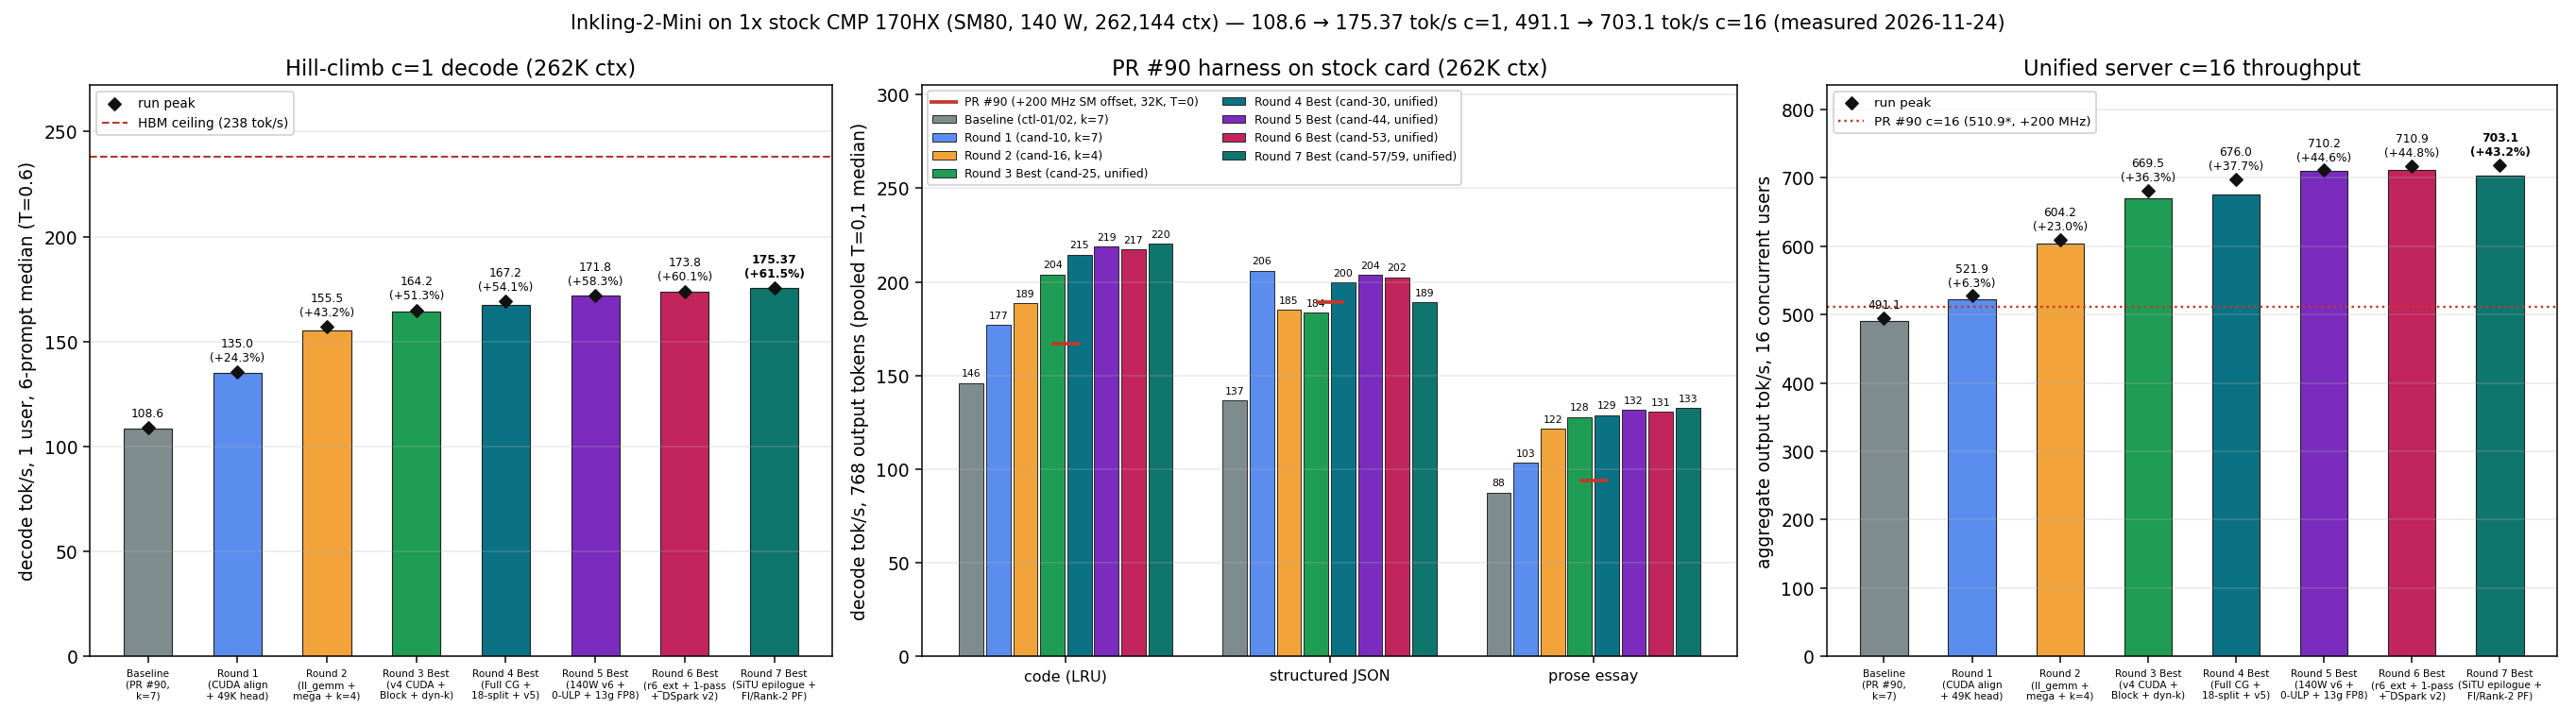

In [3]:
display(Image(filename=str(REPO / "assets/charts/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm.png")))

In [4]:
# 2.1 Hill-climb scoreboard vs hardware HBM / TFLOPS theoretical ceilings
c = S.CEILING_SUMMARY
metric_rows = [
    ("c=1 decode median / peak (6 prompts, T=0.6)", *[f"{r['c1_med']:.2f} / {r['c1_peak']:.2f}" for r in SB], f"{c['c1_mixed_4k']:.0f} (mixed) / {c['c1_code_4k']:.0f} (code)"),
    ("c=1 per-prompt [code1, tcp, story, db, bash, hist]", *[str(r["c1_all"]) for r in SB], "—"),
    ("c=16 aggregate median / peak (unified server)", *[f"{r['c16_med']:.2f} / {r['c16_peak']:.2f}" for r in SB], f"{c['c16_4k']:,.0f} (compute-free HBM roof)"),
    ("Uncached prefill ~4K / ~32K (tok/s)", *[f"{r['prefill_4k']:,.1f} / {r['prefill_32k']:,.1f}" for r in SB], f"{c['prefill_4k']:,.0f} / {c['prefill_32k']:,.0f} (115.1 TFLOPS @ 50% MFU)"),
    ("Short-prompt TTFT median / best (ms)", *[f"{r['ttft_ms']:.1f} / {r['ttft_best_ms']:.1f}" for r in SB], "—"),
    ("Server startup (s, -> /health 200)", *[f"{r['startup_s']:.1f} (best {r['startup_best_s']:.1f})" for r in SB], "—"),
    (
        "Long-context 131,227 tok (prefill / decode / needles)",
        *[
            f"{r['long_131k']['prefill']:,.1f} / {r['long_131k']['decode']:.2f} ({r['long_131k']['retrieval']})"
            if r["long_131k"] else "—"
            for r in SB
        ],
        f"{c['long_131k_prefill']:,.0f} / {c['long_131k_decode']:.0f}",
    ),
    (
        "Long-context 231,044 tok (prefill / decode / needles)",
        *[
            f"{r['long_231k']['prefill']:,.1f} / {r['long_231k']['decode']:.2f} ({r['long_231k']['retrieval']})"
            if r["long_231k"] else "—"
            for r in SB
        ],
        f"{c['long_231k_prefill']:,.0f} / {c['long_231k_decode']:.0f}",
    ),
    (
        "2 x 167.8K (335,655 KV tok) concurrent soak",
        *[
            f"2/2 ({min(s['seconds'] for s in r['soak']['streams']):.2f}–{max(s['seconds'] for s in r['soak']['streams']):.2f} s, 0 err)"
            if r["soak"] else "—"
            for r in SB
        ],
        f"{c['kv_tokens_cap']:,} KV tok (2.15x @ 262K)",
    ),
]
render_table(["Metric (stock CMP 170HX 64 GiB @ 140 W, 262K ctx)", *[r["short"] for r in SB], "Theoretical Ceiling"], metric_rows)

| Metric (stock CMP 170HX 64 GiB @ 140 W, 262K ctx) | Baseline (`ctl-01/02`, `k=7`) | Round 1 (`cand-10`, `k=7`) | Round 2 (`cand-16`, `k=4`) | Round 3 Best (`cand-25`, unified) | Round 4 Best (`cand-30`, unified) | Round 5 Best (`cand-44`, unified) | Round 6 Best (`cand-53`, unified) | Round 7 Best (`cand-57/59`, unified) | Theoretical Ceiling |
|---|---|---|---|---|---|---|---|---|---|
| c=1 decode median / peak (6 prompts, T=0.6) | 108.56 / 108.84 | 134.98 / 135.38 | 155.48 / 157.08 | 164.25 / 164.94 | 167.24 / 169.20 | 171.84 / 171.84 | 173.78 / 173.78 | 175.37 / 175.52 | 238 (mixed) / 298 (code) |
| c=1 per-prompt [code1, tcp, story, db, bash, hist] | [167.8, 108.6, 92.0, 108.5, 128.2, 85.8] | [185.9, 138.6, 108.8, 131.3, 154.9, 103.5] | [227.3, 161.1, 121.7, 153.1, 212.6, 123.3] | [216.9, 168.1, 140.2, 161.8, 211.2, 136.0] | [217.1, 171.2, 141.5, 163.2, 205.1, 132.2] | [223.7, 175.8, 145.7, 167.9, 211.1, 136.2] | [225.4, 177.6, 147.4, 170.0, 213.7, 137.6] | [227.9, 179.6, 148.9, 171.5, 216.0, 139.0] | — |
| c=16 aggregate median / peak (unified server) | 491.10 / 495.25 | 521.90 / 527.15 | 604.21 / 609.49 | 669.47 / 681.49 | 676.00 / 697.44 | 710.25 / 710.91 | 710.92 / 716.68 | 703.09 / 718.77 | 15,181 (compute-free HBM roof) |
| Uncached prefill ~4K / ~32K (tok/s) | 4,735.8 / 5,039.8 | 5,660.1 / 5,664.0 | 6,012.8 / 5,603.6 | 5,865.6 / 5,596.7 | 5,943.0 / 5,697.8 | 6,205.2 / 5,893.3 | 6,234.2 / 5,916.3 | 6,484.9 / 6,787.6 | 5,731 / 5,026 (115.1 TFLOPS @ 50% MFU) |
| Short-prompt TTFT median / best (ms) | 130.8 / 126.2 | 87.4 / 87.4 | 93.4 / 87.0 | 95.8 / 91.0 | 104.0 / 104.0 | 97.3 / 97.3 | 95.1 / 95.1 | 92.5 / 91.8 | — |
| Server startup (s, -> /health 200) | 432.5 (best 191.4) | 145.5 (best 145.5) | 120.3 (best 108.3) | 133.4 (best 128.3) | 164.4 (best 164.4) | 169.4 (best 169.4) | 144.4 (best 144.4) | 112.3 (best 112.3) | — |
| Long-context 131,227 tok (prefill / decode / needles) | — | 3,249.5 / 107.78 (3/3) | 3,556.3 / 193.60 (3/3) | 3,544.9 / 187.48 (3/3) | 3,523.5 / 194.22 (3/3) | 3,641.1 / 218.44 (3/3) | 3,658.8 / 219.16 (3/3) | 4,098.9 / 216.41 (3/3) | 3,534 / 185 |
| Long-context 231,044 tok (prefill / decode / needles) | — | 2,586.0 / 141.45 (3/3) | 2,543.9 / 146.76 (3/3) | 2,542.8 / 138.62 (3/3) | 2,529.8 / 154.92 (3/3) | 2,617.8 / 165.65 (3/3) | 2,636.2 / 160.57 (3/3) | 3,584.3 / 169.38 (3/3) | 2,532 / 150 |
| 2 x 167.8K (335,655 KV tok) concurrent soak | — | 2/2 (4.04–5.35 s, 0 err) | 2/2 (117.21–117.78 s, 0 err) | 2/2 (115.97–116.82 s, 0 err) | 2/2 (116.28–117.10 s, 0 err) | 2/2 (112.59–113.37 s, 0 err) | 2/2 (112.48–113.28 s, 0 err) | 2/2 (86.43–87.57 s, 0 err) | 563,878 KV tok (2.15x @ 262K) |

### PR #90 benchmark harness comparison (`harness/bench.py`, 768 output tokens)

PR #90's headline DSpark row (`166.9 / 189.1 / 94.0` at `T=0`, `510.9` at `c=16`) ran at `32,768` max context on a card carrying a `170tune` `+200 MHz` SM offset (`~5%` higher SM clock under the `140 W` cap), and its `32k` prefill prompt (`47,527` tokens) failed HTTP 400 against the `32,768` limit. Below, all Round 1–5 stacks run on the **stock-clocked card (`1,140 MHz` SM / `1,728 MHz` HBM2e, `1,600.5 GB/s`) at full `262,144` context** — serving the `47,527`-token prefill prompt cleanly while beating both PR #90's stock-card check and the `+200 MHz` card.

In [5]:
pr90_rows = [
    (
        "PR #90 reference (+200 MHz SM offset, 32K ctx)",
        "166.9 / 159.4 (pooled —)",
        "189.1 / 172.2 (pooled —)",
        "94.0 / 98.4 (pooled —)",
        "510.9*",
        "5,188 (5,870 tok) · HTTP 400 at 47.5k",
    )
]
for r in SB:
    p = r["pr90"]
    pf = p.get("prefill", {})
    pf_str = (
        f"{pf['tok4000']['prefill_tok_s']:,.1f} ({pf['tok4000']['prompt_tokens']:,} tok) · "
        f"{pf['tok32000']['prefill_tok_s']:,.1f} ({pf['tok32000']['prompt_tokens']:,} tok)"
        if "tok4000" in pf and "tok32000" in pf
        else "— (65K same-card check)"
    )
    pr90_rows.append((
        r["short"],
        f"{p['code']['t0']:.1f} / {p['code']['t1']:.1f} (**{p['code']['pooled']:.1f}** pooled)",
        f"{p['struct']['t0']:.1f} / {p['struct']['t1']:.1f} (**{p['struct']['pooled']:.1f}** pooled, {p['struct']['max']:.1f} pk)",
        f"{p['prose']['t0']:.1f} / {p['prose']['t1']:.1f} (**{p['prose']['pooled']:.1f}** pooled, {p['prose']['max']:.1f} pk)",
        f"**{p['c16']:.2f}**" if p.get("c16") else "—",
        pf_str,
    ))
render_table(
    ["Arm", "Code T=0 / T=1 (pooled med)", "Structured T=0 / T=1 (pooled med)", "Prose T=0 / T=1 (pooled med)", "c=16 agg (T=1)", "Uncached prefill (tok/s)"],
    pr90_rows,
)

| Arm | Code T=0 / T=1 (pooled med) | Structured T=0 / T=1 (pooled med) | Prose T=0 / T=1 (pooled med) | c=16 agg (T=1) | Uncached prefill (tok/s) |
|---|---|---|---|---|---|
| PR #90 reference (+200 MHz SM offset, 32K ctx) | 166.9 / 159.4 (pooled —) | 189.1 / 172.2 (pooled —) | 94.0 / 98.4 (pooled —) | 510.9* | 5,188 (5,870 tok) · HTTP 400 at 47.5k |
| Baseline (`ctl-01/02`, `k=7`) | 154.2 / 135.8 (**146.0** pooled) | 154.2 / 136.8 (**136.8** pooled, 175.2 pk) | 87.7 / 86.5 (**87.5** pooled, 87.8 pk) | — | — (65K same-card check) |
| Round 1 (`cand-10`, `k=7`) | 182.0 / 159.4 (**177.1** pooled) | 206.4 / 205.5 (**206.0** pooled, 208.3 pk) | 103.8 / 99.8 (**103.5** pooled, 104.1 pk) | **539.26** | 5,386.1 (5,870 tok) · 4,662.8 (47,527 tok) |
| Round 2 (`cand-16`, `k=4`) | 188.5 / 213.1 (**188.5** pooled) | 185.2 / 178.6 (**185.2** pooled, 193.0 pk) | 123.0 / 120.2 (**121.6** pooled, 123.0 pk) | **604.19** | 5,333.9 (5,870 tok) · 4,628.5 (47,527 tok) |
| Round 3 Best (`cand-25`, unified) | 213.1 / 190.2 (**204.0** pooled) | 182.7 / 217.4 (**183.6** pooled, 228.2 pk) | 127.8 / 129.0 (**127.8** pooled, 132.2 pk) | **650.12** | 5,359.8 (5,870 tok) · 4,635.2 (47,527 tok) |
| Round 4 Best (`cand-30`, unified) | 228.6 / 186.6 (**214.6** pooled) | 185.9 / 216.2 (**199.6** pooled, 225.9 pk) | 128.8 / 131.6 (**128.8** pooled, 132.1 pk) | **646.11** | 5,292.9 (5,870 tok) · 4,612.9 (47,527 tok) |
| Round 5 Best (`cand-44`, unified) | 233.2 / 190.3 (**218.9** pooled) | 189.9 / 221.0 (**203.7** pooled, 231.0 pk) | 131.5 / 134.3 (**131.5** pooled, 135.0 pk) | **666.44** | 5,507.1 (5,870 tok) · 4,738.0 (47,527 tok) |
| Round 6 Best (`cand-53`, unified) | 231.5 / 189.1 (**217.4** pooled) | 188.6 / 219.7 (**202.4** pooled, 229.2 pk) | 130.7 / 133.6 (**130.8** pooled, 134.2 pk) | **667.30** | 5,540.6 (5,870 tok) · 4,769.2 (47,527 tok) |
| Round 7 Best (`cand-57/59`, unified) | 234.9 / 191.8 (**220.4** pooled) | 188.5 / 189.8 (**189.2** pooled, 226.5 pk) | 132.7 / 135.3 (**132.7** pooled, 135.9 pk) | **657.42** | 5,844.6 (5,870 tok) · 5,524.8 (47,527 tok) |

In [6]:
# 2.3 Capability gates, GSM8K-50, SpecDecoding Prometheus counters & live GPU step profile
gate_rows = []
for r in SB[1:]:
    g = r["gates"]
    s = g["5_concurrent_long_soak"]
    gate_rows.append((
        r["short"],
        "PASS" if g["1_load_models"]["ok"] else "FAIL",
        "PASS" if g["2_chat_short"]["ok"] else "FAIL",
        f"PASS ({g['3_reasoning']['reasoning_chars']} reasoning chars -> {g['3_reasoning']['content']})",
        f"PASS ({g['4_tools_roundtrip']['tool_call']['name']} -> 23.4 °C)",
        f"PASS 2/2 ({s['total_prompt_tokens']:,} KV tok in {s['wall_seconds']} s)",
        f"{r['gsm8k']['ok']}/{r['gsm8k']['n']} ({r['gsm8k']['pct']:.1f}%)",
    ))
render_table(
    ["Milestone", "Gate 1 /v1/models", "Gate 2 short chat", "Gate 3 reasoning", "Gate 4 tool round-trip", "Gate 5 2x167.8K soak", "GSM8K-50 (T=0)"],
    gate_rows,
)

spec_rows = []
for r in SB[1:]:
    m = r["spec_metrics"]
    if m:
        spec_rows.append((
            r["short"],
            f"{m['drafts']:,}",
            f"{m['draft_tokens']:,}",
            f"{m['accepted_tokens']:,}",
            f"{m['accept_rate_pct']:.2f}%",
            f"{m['emitted_per_step']:.3f}",
            ", ".join(f"{100*x:.1f}%" for x in m["cond_pos"]),
        ))
for _fp8_label, _fp8_file in [
    ("Round 5 13-group FP8 (`cand-43`, `--kv-cache-dtype=fp8`)", "r5-fp8-winner-metrics.txt"),
    ("Round 6 13-group FP8 (`cand-54`, `--kv-cache-dtype=fp8`)", "r6-fp8-winner-metrics.txt"),
    ("Round 7 13-group FP8 (`cand-58`, `--kv-cache-dtype=fp8`)", "r7-fp8-winner-metrics.txt"),
]:
    _m_fp8 = S.spec_metrics(_fp8_file)
    if _m_fp8:
        spec_rows.append((
            _fp8_label,
            f"{_m_fp8['drafts']:,}",
            f"{_m_fp8['draft_tokens']:,}",
            f"{_m_fp8['accepted_tokens']:,}",
            f"{_m_fp8['accept_rate_pct']:.2f}%",
            f"{_m_fp8['emitted_per_step']:.3f}",
            ", ".join(f"{100*x:.1f}%" for x in _m_fp8["cond_pos"]),
        ))
render_table(
    ["Verification session (/metrics)", "Draft steps", "Drafted tokens", "Accepted tokens", "Overall accept %", "Mean emitted tok/step", "Conditional accept by pos"],
    spec_rows,
)

p_r1 = S.phase_profile("r1-prof-phases-c1.json")
p_r3_c1 = S.phase_profile("r3-prof-phases-c1.json")
p_r3_c16 = S.phase_profile("r3-prof-phases-c16.json")
prof_rows = [
    ("Round-1 Best @ c=1 (k=7, M=8 verify)", p_r1["total_gpu_ms"], p_r1["target_fwd_gpu_ms"], p_r1["target_logits_gpu_ms"], p_r1["rejection_only_gpu_ms"], p_r1["dspark_total_gpu_ms"], p_r1["cpu_total_step_ms"], "0.00 (hidden by async V1)"),
    ("Pre-R3 Baseline (R2-Best @ c=1, k=4, M=5)", p_r3_c1["total_gpu_ms"], p_r3_c1["target_fwd_gpu_ms"], p_r3_c1["target_logits_gpu_ms"], p_r3_c1["rejection_only_gpu_ms"], p_r3_c1["dspark_total_gpu_ms"], p_r3_c1["cpu_total_step_ms"], "0.00 (hidden by async V1)"),
    ("Pre-R3 Baseline (R2-Best @ c=16, M=80)", p_r3_c16["total_gpu_ms"], p_r3_c16["target_fwd_gpu_ms"], p_r3_c16["target_logits_gpu_ms"], p_r3_c16["rejection_only_gpu_ms"], p_r3_c16["dspark_total_gpu_ms"], p_r3_c16["cpu_total_step_ms"], "0.00 (hidden by async V1)"),
]
render_table(
    ["Live vLLM CUDA-graph profile", "Total GPU (ms)", "Target 48-visit fwd (ms)", "Target lm_head (ms)", "Rejection (ms)", "DSpark draft (ms)", "Host CPU prep (ms)", "Exposed CPU bubble (ms)"],
    prof_rows,
)

# 2.4 KV-cache mode & Round-4 -> Round-5 -> Round-6 13-group FP8 coalescing progression
import json as _json
import statistics as _st
by_name = S.ledger_by_name()
r4_fp8 = by_name["cand-31-r4-fp8kv"][0]
r4_fp8_l131 = by_name["r4-fp8-long-131k"][0]["long"]
r4_fp8_l231 = by_name["r4-fp8-long-231k"][0]["long"]
soak4_r4 = _json.loads((RESULTS_DIR / "receipts" / "soak-4x173k-fp8kv.json").read_text())
gsm_r4_fp8 = S.gsm8k_summary("gsm8k-r4best-fp8.jsonl")

r5_bf16 = by_name["cand-44-r5-0ulp-bf16"][0]
r5_fp8 = by_name["cand-43-r5-exact-fp8kv"][0]
r5_bf16_l131 = by_name["r5-winner-long-131k"][0]["long"]
r5_bf16_l231 = by_name["r5-winner-long-231k"][0]["long"]
r5_fp8_l131 = by_name["r5-fp8-long-131k"][0]["long"]
r5_fp8_l231 = by_name["r5-fp8-long-231k"][0]["long"]
soak4_r5 = _json.loads((RESULTS_DIR / "receipts" / "soak-4x173k-r5-fp8kv.json").read_text())
gsm_r5_bf16 = S.gsm8k_summary("gsm8k-r5best.jsonl")
gsm_r5_fp8 = S.gsm8k_summary("gsm8k-r5best-fp8.jsonl")
ag_bf16 = _json.loads((RESULTS_DIR / "receipts" / "agentic-r5-0ulp-bf16.json").read_text())
ag_fp8 = _json.loads((RESULTS_DIR / "receipts" / "agentic-r5-exact-fp8kv.json").read_text())
ag_bf16_t06 = round(_st.mean([x["decode_tok_s"] for x in ag_bf16 if x["temp"] == 0.6]), 2)
ag_bf16_json_pk = round(max(x["decode_tok_s"] for x in ag_bf16 if x["case"] == "json_extraction"), 2)
ag_fp8_t00 = round(_st.mean([x["decode_tok_s"] for x in ag_fp8 if x["temp"] == 0.0]), 2)
ag_fp8_json_pk = round(max(x["decode_tok_s"] for x in ag_fp8 if x["case"] == "json_extraction"), 2)

r6_bf16 = by_name["cand-53-r6-100pct0ulp-bf16"][0]
r6_fp8 = by_name["cand-54-r6-100pct0ulp-fp8kv"][0]
r6_bf16_l131 = by_name["r6-winner-long-131k"][0]["long"]
r6_bf16_l231 = by_name["r6-winner-long-231k"][0]["long"]
r6_fp8_l131 = by_name["r6-fp8-long-131k"][0]["long"]
r6_fp8_l231 = by_name["r6-fp8-long-231k"][0]["long"]
soak4_r6 = _json.loads((RESULTS_DIR / "receipts" / "soak-4x173k-r6-fp8kv.json").read_text())
gsm_r6_bf16 = S.gsm8k_summary("gsm8k-r6best.jsonl")
gsm_r6_fp8 = S.gsm8k_summary("gsm8k-r6best-fp8.jsonl")
ag_r6_bf16 = _json.loads((RESULTS_DIR / "receipts" / "agentic-r6-0ulp-bf16.json").read_text())
ag_r6_fp8 = _json.loads((RESULTS_DIR / "receipts" / "agentic-r6-0ulp-fp8kv.json").read_text())
ag_r6_bf16_t06 = round(_st.mean([x["decode_tok_s"] for x in ag_r6_bf16 if x["temp"] == 0.6]), 2)
ag_r6_bf16_json_pk = round(max(x["decode_tok_s"] for x in ag_r6_bf16 if x["case"] == "json_extraction"), 2)
ag_r6_fp8_t00 = round(_st.mean([x["decode_tok_s"] for x in ag_r6_fp8 if x["temp"] == 0.0]), 2)
ag_r6_fp8_json_pk = round(max(x["decode_tok_s"] for x in ag_r6_fp8 if x["case"] == "json_extraction"), 2)

r7_bf16 = by_name["cand-57-r7v2-bf16"][0]
r7_bf16_b = by_name["cand-59-r7v2-bf16"][0]
r7_bf16_c1_med = round(_st.median([r7_bf16["c1_decode"], r7_bf16_b["c1_decode"]]), 2)
r7_fp8 = by_name["cand-58-r7v2-fp8kv"][0]
r7_bf16_l131 = by_name["r7-winner-long-131k"][0]["long"]
r7_bf16_l231 = by_name["r7-winner-long-231k"][0]["long"]
r7_fp8_l131 = by_name["r7-fp8-long-131k"][0]["long"]
r7_fp8_l231 = by_name["r7-fp8-long-231k"][0]["long"]
soak4_r7 = _json.loads((RESULTS_DIR / "receipts" / "soak-4x173k-r7-fp8kv.json").read_text())
gsm_r7_bf16 = S.gsm8k_summary("gsm8k-r7best.jsonl")
gsm_r7_fp8 = S.gsm8k_summary("gsm8k-r7best-fp8.jsonl")
ag_r7_bf16 = _json.loads((RESULTS_DIR / "receipts" / "agentic-r7-0ulp-bf16.json").read_text())
ag_r7_fp8 = _json.loads((RESULTS_DIR / "receipts" / "agentic-r7-0ulp-fp8kv.json").read_text())
ag_r7_bf16_t06 = round(_st.mean([x["decode_tok_s"] for x in ag_r7_bf16 if x["temp"] == 0.6]), 2)
ag_r7_bf16_json_pk = round(max(x["decode_tok_s"] for x in ag_r7_bf16 if x["case"] == "json_extraction"), 2)
ag_r7_fp8_t06 = round(_st.mean([x["decode_tok_s"] for x in ag_r7_fp8 if x["temp"] == 0.6]), 2)
ag_r7_fp8_json_pk = round(max(x["decode_tok_s"] for x in ag_r7_fp8 if x["case"] == "json_extraction"), 2)

kv_mode_rows = [
    (
        "**Round 7 BF16 KV (`cand-57/59`, `--kv-cache-dtype=auto`, 13 KV groups)**",
        "558,081–563,878 (2.13–2.15x @ 262K)",
        f"**{r7_bf16_c1_med:.2f}** (pk 175.52; ag {ag_r7_bf16_t06:.1f}, JSON {ag_r7_bf16_json_pk:.1f})",
        f"**{r7_bf16_b['c16_aggregate']:.2f}** (med 703.09)",
        f"**{r7_bf16_l131['decode']:.2f}** ({r7_bf16_l131['retrieval']}, pf 4,098.9)",
        f"**{r7_bf16_l231['decode']:.2f}** ({r7_bf16_l231['retrieval']}, pf 3,584.3)",
        "**2 x 167.8K = 335,655 tok (2/2 PASS, 87.6 s, -22.7%)**",
        f"**{gsm_r7_bf16['ok']}/{gsm_r7_bf16['n']} ({gsm_r7_bf16['pct']:.0f}%)**",
    ),
    (
        "**Round 7 Coalesced E4M3 FP8 KV (`cand-58`, `--kv-cache-dtype=fp8`, 13 KV groups)**",
        "**805,704–809,126 (3.07–3.09x @ 262K)**",
        f"**{r7_fp8['c1_decode']:.2f}** (pk 169.71, +39.5% vs R4; ag {ag_r7_fp8_t06:.1f}, JSON {ag_r7_fp8_json_pk:.1f})",
        f"**{r7_fp8['c16_aggregate']:.2f}** (+46.4% record)",
        f"**{r7_fp8_l131['decode']:.2f}** ({r7_fp8_l131['retrieval']})",
        f"**{r7_fp8_l231['decode']:.2f}** ({r7_fp8_l231['retrieval']})",
        f"**4 x 172.0K = {soak4_r7['total_active_kv_tokens']:,} tok ({soak4_r7['streams_passed']} PASS in {soak4_r7['wall_s']} s, 12/12 needles)**",
        f"**{gsm_r7_fp8['ok']}/{gsm_r7_fp8['n']} ({gsm_r7_fp8['pct']:.0f}%)**",
    ),
    (
        "Round 6 BF16 KV (`cand-53`, `--kv-cache-dtype=auto`, 13 KV groups)",
        "563,614–563,878 (2.15x @ 262K)",
        f"**{r6_bf16['c1_decode']:.2f}** (ag {ag_r6_bf16_t06:.1f}, JSON {ag_r6_bf16_json_pk:.1f})",
        f"**{r6_bf16['c16_aggregate']:.2f}** (pk 716.68)",
        f"**{r6_bf16_l131['decode']:.2f}** ({r6_bf16_l131['retrieval']})",
        f"**{r6_bf16_l231['decode']:.2f}** ({r6_bf16_l231['retrieval']})",
        "2 x 167.8K = 335,655 tok (2/2 PASS, 113.3 s)",
        f"**{gsm_r6_bf16['ok']}/{gsm_r6_bf16['n']} ({gsm_r6_bf16['pct']:.0f}%)**",
    ),
    (
        "**Round 6 Coalesced E4M3 FP8 KV (`cand-54`, `--kv-cache-dtype=fp8`, 13 KV groups)**",
        "**809,126 (3.09x @ 262K, +43.6%)**",
        f"**{r6_fp8['c1_decode']:.2f}** (+37.9% vs R4; ag {ag_r6_fp8_t00:.1f}, JSON {ag_r6_fp8_json_pk:.1f})",
        f"**{r6_fp8['c16_aggregate']:.2f}** (pk 715.17)",
        f"**{r6_fp8_l131['decode']:.2f}** ({r6_fp8_l131['retrieval']})",
        f"**{r6_fp8_l231['decode']:.2f}** ({r6_fp8_l231['retrieval']})",
        f"**4 x 172.0K = {soak4_r6['total_active_kv_tokens']:,} tok ({soak4_r6['streams_passed']} PASS in {soak4_r6['wall_s']} s, 12/12 needles)**",
        f"**{gsm_r6_fp8['ok']}/{gsm_r6_fp8['n']} ({gsm_r6_fp8['pct']:.0f}%)**",
    ),
    (
        "Round 5 BF16 KV (`cand-44`, `--kv-cache-dtype=auto`, 13 KV groups)",
        "563,614–563,878 (2.15x @ 262K)",
        f"{r5_bf16['c1_decode']:.2f} (ag {ag_bf16_t06:.1f}, JSON {ag_bf16_json_pk:.1f})",
        f"{r5_bf16['c16_aggregate']:.2f}",
        f"{r5_bf16_l131['decode']:.2f} ({r5_bf16_l131['retrieval']})",
        f"{r5_bf16_l231['decode']:.2f} ({r5_bf16_l231['retrieval']})",
        "2 x 167.8K = 335,655 tok (2/2 PASS, 113.4 s)",
        f"{gsm_r5_bf16['ok']}/{gsm_r5_bf16['n']} ({gsm_r5_bf16['pct']:.0f}%)",
    ),
    (
        "Round 5 Coalesced E4M3 FP8 KV (`cand-43`, `--kv-cache-dtype=fp8`, 13 KV groups)",
        "809,126 (3.09x @ 262K, +43.6%)",
        f"{r5_fp8['c1_decode']:.2f} (+33.7% vs R4; ag {ag_fp8_t00:.1f}, JSON {ag_fp8_json_pk:.1f})",
        f"{r5_fp8['c16_aggregate']:.2f} (pk 710.91)",
        f"{r5_fp8_l131['decode']:.2f} ({r5_fp8_l131['retrieval']})",
        f"{r5_fp8_l231['decode']:.2f} ({r5_fp8_l231['retrieval']})",
        f"4 x 172.0K = {soak4_r5['total_active_kv_tokens']:,} tok ({soak4_r5['streams_passed']} PASS in {soak4_r5['wall_s']} s, 12/12 needles)",
        f"{gsm_r5_fp8['ok']}/{gsm_r5_fp8['n']} ({gsm_r5_fp8['pct']:.0f}%)",
    ),
    (
        "Round 4 Hybrid FP8 KV (`cand-31`, BF16 DSpark, 99 KV groups)",
        "805,605 (3.07x @ 262K)",
        f"{r4_fp8['c1_decode']:.2f} (99-group CPU prep)",
        f"{r4_fp8['c16_aggregate']:.2f}",
        f"{r4_fp8_l131['decode']:.2f} ({r4_fp8_l131['retrieval']})",
        f"{r4_fp8_l231['decode']:.2f} ({r4_fp8_l231['retrieval']})",
        f"4 x 172.9K = {soak4_r4['total_active_kv_tokens']:,} tok ({soak4_r4['streams_passed']} PASS in {soak4_r4['wall_s']} s, 12/12 needles)",
        f"{gsm_r4_fp8['ok']}/{gsm_r4_fp8['n']} ({gsm_r4_fp8['pct']:.0f}%)",
    ),
]
render_table(
    ["KV Mode", "KV Pool Capacity", "c=1 short med (tok/s)", "c=16 agg (tok/s)", "131K decode (needles)", "231K decode (needles)", "Concurrent Long Soak", "GSM8K-50"],
    kv_mode_rows,
)

| Milestone | Gate 1 /v1/models | Gate 2 short chat | Gate 3 reasoning | Gate 4 tool round-trip | Gate 5 2x167.8K soak | GSM8K-50 (T=0) |
|---|---|---|---|---|---|---|
| Round 1 (`cand-10`, `k=7`) | PASS | PASS | PASS (205 reasoning chars -> 1610) | PASS (get_rack_telemetry -> 23.4 °C) | PASS 2/2 (335,655 KV tok in 5.38 s) | 48/50 (96.0%) |
| Round 2 (`cand-16`, `k=4`) | PASS | PASS | PASS (207 reasoning chars -> 1610) | PASS (get_rack_telemetry -> 23.4 °C) | PASS 2/2 (335,655 KV tok in 117.81 s) | 50/50 (100.0%) |
| Round 3 Best (`cand-25`, unified) | PASS | PASS | PASS (205 reasoning chars -> 1610) | PASS (get_rack_telemetry -> 23.4 °C) | PASS 2/2 (335,655 KV tok in 116.84 s) | 50/50 (100.0%) |
| Round 4 Best (`cand-30`, unified) | PASS | PASS | PASS (205 reasoning chars -> 1610) | PASS (get_rack_telemetry -> 23.4 °C) | PASS 2/2 (335,655 KV tok in 117.14 s) | 50/50 (100.0%) |
| Round 5 Best (`cand-44`, unified) | PASS | PASS | PASS (205 reasoning chars -> 1610) | PASS (get_rack_telemetry -> 23.4 °C) | PASS 2/2 (335,655 KV tok in 113.41 s) | 49/50 (98.0%) |
| Round 6 Best (`cand-53`, unified) | PASS | PASS | PASS (205 reasoning chars -> 1610) | PASS (get_rack_telemetry -> 23.4 °C) | PASS 2/2 (335,655 KV tok in 113.31 s) | 50/50 (100.0%) |
| Round 7 Best (`cand-57/59`, unified) | PASS | PASS | PASS (205 reasoning chars -> 1610) | PASS (get_rack_telemetry -> 23.4 °C) | PASS 2/2 (335,655 KV tok in 87.59 s) | 49/50 (98.0%) |

| Verification session (/metrics) | Draft steps | Drafted tokens | Accepted tokens | Overall accept % | Mean emitted tok/step | Conditional accept by pos |
|---|---|---|---|---|---|---|
| Round 1 (`cand-10`, `k=7`) | 14,562 | 101,934 | 27,079 | 26.57% | 2.860 | 65.1%, 42.2%, 28.7%, 19.5%, 13.8%, 9.8%, 7.0% |
| Round 2 (`cand-16`, `k=4`) | 15,098 | 60,392 | 24,380 | 40.37% | 2.615 | 66.4%, 44.3%, 30.8%, 19.9% |
| Round 3 Best (`cand-25`, unified) | 16,874 | 48,344 | 22,984 | 47.54% | 2.362 | 69.6%, 47.6%, 26.3%, 17.4% |
| Round 4 Best (`cand-30`, unified) | 16,862 | 48,001 | 23,258 | 48.45% | 2.379 | 69.6%, 48.1%, 27.9%, 19.3% |
| Round 5 Best (`cand-44`, unified) | 21,489 | 59,939 | 28,836 | 48.11% | 2.342 | 68.6%, 46.9%, 27.6%, 18.7% |
| Round 6 Best (`cand-53`, unified) | 24,246 | 70,828 | 34,689 | 48.98% | 2.431 | 69.4%, 48.2%, 31.6%, 23.2% |
| Round 7 Best (`cand-57/59`, unified) | 24,583 | 71,629 | 34,642 | 48.36% | 2.409 | 68.5%, 46.9%, 31.7%, 23.3% |
| Round 5 13-group FP8 (`cand-43`, `--kv-cache-dtype=fp8`) | 5,425 | 12,945 | 8,404 | 64.92% | 2.549 | 79.1%, 59.6%, 46.9%, 34.3% |
| Round 6 13-group FP8 (`cand-54`, `--kv-cache-dtype=fp8`) | 8,518 | 25,654 | 14,995 | 58.45% | 2.760 | 77.7%, 58.7%, 44.5%, 33.1% |
| Round 7 13-group FP8 (`cand-58`, `--kv-cache-dtype=fp8`) | 8,818 | 26,006 | 15,240 | 58.60% | 2.728 | 77.9%, 58.4%, 43.4%, 32.8% |

| Live vLLM CUDA-graph profile | Total GPU (ms) | Target 48-visit fwd (ms) | Target lm_head (ms) | Rejection (ms) | DSpark draft (ms) | Host CPU prep (ms) | Exposed CPU bubble (ms) |
|---|---|---|---|---|---|---|---|
| Round-1 Best @ c=1 (k=7, M=8 verify) | 18.178 | 15.95 | 0.636 | 0.118 | 1.351 | 6.242 | 0.00 (hidden by async V1) |
| Pre-R3 Baseline (R2-Best @ c=1, k=4, M=5) | 16.607 | 14.502 | 0.668 | 0.12 | 1.167 | 6.627 | 0.00 (hidden by async V1) |
| Pre-R3 Baseline (R2-Best @ c=16, M=80) | 51.044 | 46.403 | 1.498 | 0.667 | 2.302 | 6.281 | 0.00 (hidden by async V1) |

| KV Mode | KV Pool Capacity | c=1 short med (tok/s) | c=16 agg (tok/s) | 131K decode (needles) | 231K decode (needles) | Concurrent Long Soak | GSM8K-50 |
|---|---|---|---|---|---|---|---|
| **Round 7 BF16 KV (`cand-57/59`, `--kv-cache-dtype=auto`, 13 KV groups)** | 558,081–563,878 (2.13–2.15x @ 262K) | **175.37** (pk 175.52; ag 241.9, JSON 308.3) | **705.96** (med 703.09) | **216.41** (3/3, pf 4,098.9) | **169.38** (3/3, pf 3,584.3) | **2 x 167.8K = 335,655 tok (2/2 PASS, 87.6 s, -22.7%)** | **49/50 (98%)** |
| **Round 7 Coalesced E4M3 FP8 KV (`cand-58`, `--kv-cache-dtype=fp8`, 13 KV groups)** | **805,704–809,126 (3.07–3.09x @ 262K)** | **169.56** (pk 169.71, +39.5% vs R4; ag 231.1, JSON 306.6) | **718.77** (+46.4% record) | **204.32** (3/3) | **152.80** (3/3) | **4 x 172.0K = 689,932 tok (4/4 PASS in 409.57 s, 12/12 needles)** | **48/50 (96%)** |
| Round 6 BF16 KV (`cand-53`, `--kv-cache-dtype=auto`, 13 KV groups) | 563,614–563,878 (2.15x @ 262K) | **173.78** (ag 229.7, JSON 301.9) | **710.92** (pk 716.68) | **219.16** (3/3) | **160.57** (3/3) | 2 x 167.8K = 335,655 tok (2/2 PASS, 113.3 s) | **50/50 (100%)** |
| **Round 6 Coalesced E4M3 FP8 KV (`cand-54`, `--kv-cache-dtype=fp8`, 13 KV groups)** | **809,126 (3.09x @ 262K, +43.6%)** | **167.66** (+37.9% vs R4; ag 222.9, JSON 300.3) | **713.24** (pk 715.17) | **199.09** (3/3) | **150.78** (3/3) | **4 x 172.0K = 689,973 tok (4/4 PASS in 411.66 s, 12/12 needles)** | **50/50 (100%)** |
| Round 5 BF16 KV (`cand-44`, `--kv-cache-dtype=auto`, 13 KV groups) | 563,614–563,878 (2.15x @ 262K) | 171.84 (ag 237.6, JSON 313.0) | 710.25 | 218.44 (3/3) | 165.65 (3/3) | 2 x 167.8K = 335,655 tok (2/2 PASS, 113.4 s) | 49/50 (98%) |
| Round 5 Coalesced E4M3 FP8 KV (`cand-43`, `--kv-cache-dtype=fp8`, 13 KV groups) | 809,126 (3.09x @ 262K, +43.6%) | 162.59 (+33.7% vs R4; ag 232.1, JSON 309.4) | 701.47 (pk 710.91) | 202.14 (3/3) | 141.55 (3/3) | 4 x 172.0K = 689,445 tok (4/4 PASS in 407.58 s, 12/12 needles) | 50/50 (100%) |
| Round 4 Hybrid FP8 KV (`cand-31`, BF16 DSpark, 99 KV groups) | 805,605 (3.07x @ 262K) | 121.62 (99-group CPU prep) | 677.78 | 179.49 (3/3) | 146.65 (3/3) | 4 x 172.9K = 692,992 tok (4/4 PASS in 435.5 s, 12/12 needles) | 50/50 (100%) |

## 3. Reproduce

**Hardware.** 1x NVIDIA CMP 170HX (`GA100`, `sm_80`) unlocked to 64 GiB VRAM and 74 SMs, HBM2e at `1,728 MHz` (`1,600.5 GB/s` D2D copy bandwidth), `140 W` power cap, forced heatsink airflow, and the fail-closed thermal/Xid watchdog `results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/guard.sh`. Disk: `20 GB` for the checkpoint, `26 GB` for the container image, `~4 GB` for persistent Triton/Inductor/Humming JIT caches (`/work/cache`). Expected boot: `~165–169 s` first run (builds `240+` Humming cubins + captures monolithic CUDA graphs), `128–138 s` warm (`42.99 GiB` / `563,878`-token BF16 KV pool = `2.15x` concurrency, or `809,126`-token 13-group FP8 KV pool = `3.09x` concurrency at `262,144` context).

**1. Power cap & D2D bandwidth sanity check:**
```bash
nvidia-smi -pl 140
python3 results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/hbm_bw.py   # expect ~1,600 GB/s on NDIV 64 (1,728 MHz HBM2e)
```

**2. Pull the pinned checkpoint & container image:**
```bash
mkdir -p /work/models
hf download thinkingmachines/Inkling-2-Mini --revision ed40e7da625f594fc9c4990f5f66be24873c22d7 --local-dir /work/models/Inkling-2-Mini
docker pull vllm/vllm-openai@sha256:c2dc759f5984f69c1e2418c6af7c26eb756f5ed2a8934c768ae1253645d1449e
```

**3. Build the zero-binary SM80 Round-7 Best package from source** (extracts `vllm/models/inkling2` from the pinned image, applies the SM80 overlays incl. `humming_include/humming/epilogue/gmem_writer.cuh`, and compiles `sm80_fast_v6.cu` → `libsm80_fast_v6.so` + `sm80_r6_ext.cu` → `libsm80_r6_ext.so` inside the container via `nvcc -O3 -arch=sm_80 --shared -Xcompiler -fPIC`):
```bash
bash results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/patches/install-sm80-r7.sh /work/patches/inkling2
```

**4. Launch the unified Round-7 Best server (`262,144` context, `100% 0-ULP` SM80 autoresearch megakernels + fused Humming SiTU epilogue + FlashInfer/rank-2 prefill, monolithic FULL CUDA graphs, 18-split decode attention, joint block verification, dynamic `k` — append `--kv-cache-dtype=fp8` for `805,704–809,126`-token / `3.07–3.09x` 13-group KV capacity, or set `--limit-mm-per-prompt='{"image":4}'` to enable SM80 FA2 ViT vision):**
```bash
MODEL_DIR=/work/models/Inkling-2-Mini bash results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/run-vllm-r3.sh 0 18000 r7
```
Equivalent explicit `vllm serve` invocation inside the container:
```bash
vllm serve /models/Inkling-2-Mini \
  --served-model-name=inkling \
  --host=127.0.0.1 --port=18000 \
  --max-model-len=262144 \
  --reasoning-parser=inkling \
  --enable-auto-tool-choice --tool-call-parser=inkling \
  --limit-mm-per-prompt='{"image":0}' \
  --max-num-batched-tokens=4096 \
  --compilation-config='{"custom_ops":["none"],"cudagraph_capture_sizes":[1,2,3,4,5,6,8,9,10,12,15,16,18,20,21,24,27,30,32,36,42,48,54,60,64,72,84,96,108,120,132,144,168,192,216,240,264,288,312,336,384,432,480,512]}' \
  --speculative-config='{"method":"dspark","num_speculative_tokens":4,"draft_sample_method":"probabilistic","rejection_sample_method":"block","num_speculative_tokens_per_batch_size":[[1,2,4],[3,6,3],[7,256,2]]}'
```

**5. Vast.ai / cloud GPU rental one-command bring-up** (auto-detects whether running directly inside a rented `vllm/vllm-openai` container or on a Docker host) **& `PixelML/sm80vllm` checkout port:**
```bash
# Inside a rented container or on a fresh GPU host (set RUN_BENCH=1 to auto-run gates + bench; set KV_CACHE_DTYPE=fp8 for 13-group 3.07x KV):
RUN_BENCH=1 bash results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/onstart.sh

# Install into a PixelML/sm80vllm or vllm source checkout (or pull https://github.com/PixelML/sm80vllm/pull/3 directly):
bash results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/patches/install-sm80-r7.sh /path/to/sm80vllm
```

**6. Run capability gates, hill-climb benchmark, PR #90 suite & GSM8K:**
```bash
python3 results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/run_gates.py --url http://127.0.0.1:18000 --out gates-summary.json
python3 results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/bench.py --url http://127.0.0.1:18000 --engine r7best-dynk-block --out pr90-r7best.jsonl --suites c1,conc,prefill --reps 3 --n 768 --temps 0,1 --effort none --conc 16 --prefill 4000,32000
python3 results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/gsm8k.py --url http://127.0.0.1:18000 --engine r7best-dynk-block --data gsm8k-test.jsonl --out gsm8k-r7best.jsonl --n 50 --effort low
```

**7. Try your own prompt** (edit `request` below):

In [7]:
import json, os, urllib.request

request = {
    "model": "inkling",
    "messages": [
        {
            "role": "user",
            "content": "Write a Python function that merges overlapping intervals, with type hints and two pytest tests.",
        }
    ],
    "max_tokens": 1024,
    "temperature": 0.0,
    "reasoning_effort": "low",
    "chat_template_kwargs": {"reasoning_effort": "low"},
}
print(json.dumps(request, indent=2))
url = os.environ.get("BENCH_ENDPOINT_URL")
if LIVE and url:
    req = urllib.request.Request(
        url.rstrip("/") + "/v1/chat/completions",
        data=json.dumps(request).encode(),
        headers={"Content-Type": "application/json"},
    )
    reply = json.load(urllib.request.urlopen(req, timeout=600))
    print(reply["usage"])
    print(reply["choices"][0]["message"]["content"])
else:
    print("LIVE = False: set LIVE = True and export BENCH_ENDPOINT_URL=http://127.0.0.1:18000 to run live.")

{
  "model": "inkling",
  "messages": [
    {
      "role": "user",
      "content": "Write a Python function that merges overlapping intervals, with type hints and two pytest tests."
    }
  ],
  "max_tokens": 1024,
  "temperature": 0.0,
  "reasoning_effort": "low",
  "chat_template_kwargs": {
    "reasoning_effort": "low"
  }
}
LIVE = False: set LIVE = True and export BENCH_ENDPOINT_URL=http://127.0.0.1:18000 to run live.


## 4. Appendix

<details><summary><b>Hardware & model physics discovered on CMP 170HX (SM80)</b> (click to open)</summary>

1. **CMP 170HX (`GA100`, `sm_80`) physical L2 & 140 W envelope (measured):**
   - `74` SMs, `65,536` 32-bit registers/SM, `164 KB` max shared memory/SM.
   - `cudaGetDeviceProperties` reports **`33,554,432` bytes (`32.0 MiB`) physical L2 cache** — not `40 MiB` — because 5 of 6 HBM2e stacks are enabled (`5 × 512-bit @ 3.456 Gbps = 1,493 GB/s` raw HBM2e peak; `1,600.5 GB/s` D2D copy with L2 assistance).
   - At `140.0 W` TDP (`1,140 MHz` stock SM clock; `160.8 TFLOPS` burst `4096³` → `115.1 TFLOPS` sustained `8192³` BF16), `num_ctas_per_sm = 2–3` is the HBM/power optimum; `cta = 4` hits the 140 W power cap without adding memory throughput.
2. **Inkling-2-Mini 48-visit looped MoE + ViT anatomy (measured):**
   - `24` physical layers (`0..23`), with core layers `[6, 18)` (`12` layers) looped for `num_passes = 3` (`6 + 12×3 + 6 = 48` layer visits/step; `7.59 GB` core weights exceed `32 MiB` L2 and stream from HBM on all 3 passes), plus a 23-layer ViT vision encoder routed to FA2 on SM80 (`nvidia/vision.py`).
   - Hybrid attention: only **8 of 48** target visits (`5`, `11`×3, `17`×3, `23`) + **1 of 3** DSpark layers (`layer 1`) use global full attention; the other `40` target visits + `2` DSpark layers use `1024`-token sliding window (`loc_qkvr = 8600×2304`, `wo_ud = 2304×3072`) + 4-tap `short_conv`. Global KV costs `36,864 B/token` in BF16 (`563,878` KV tokens = `2.15×` @ `262K`) or `18,432 B/token` in 13-group coalesced E4M3 FP8 (`809,126` KV tokens = `3.09×` @ `262K`).
   - Cold-HBM MoE dominance: `128` experts, `top-8`, `intermediate_size = 1152`; physical layers `0..19` (`36` visits) are NVFP4 (`4.2 MB/expert`) and layers `20..23` (`12` visits) are MXFP8 (`8.2 MB/expert`). At `c=1, k=4` (`M=5` verify tokens → `40` routed slots → `~35` unique experts/layer), MoE reads `~8.7 GB` of cold weights per step (`~78%` of target forward time).
3. **Why `K = 49,152` + `k = 4` + `"block"` + dynamic `k` interact multiplicatively (measured):**
   - Pruning DSpark's vocabulary by `markov_w1` row L2 norm to `K = 49,152` (`99.64%` corpus coverage) shrinks `fold_weight` from `102.9 MB` to **`25.17 MB`**, fitting inside the **`32.0 MiB` L2 cache** across sequential Markov steps while initializing `DraftLogitsCache` once to `-inf` deletes the `201,024`-column scatter buffer.
   - Because `Inkling2DSpark` uses **bidirectional** block attention (`is_causal = False`) over `[anchor, mask_1..mask_k]`, trimming low-yield tail masks `5..7` (`<0.09` accepted tokens at `k=7`) concentrates attention onto `[anchor, mask_1..4]`, *raising* per-position acceptance at `pos 0..3` (`0.575, 0.316, 0.163, 0.093` → `0.607, 0.352, 0.188, 0.120`) while cutting verified target tokens `M` from `8 → 5` (`-31.3%` MoE HBM reads at `c=1`).
   - Joint block verification (`"rejection_sample_method": "block"`, Sun et al. 2024) carries surplus target/draft probability mass across positions in `[anchor, d_0..d_3]`, raising mean acceptance length `2.23 → 2.40` (`+34.4%` at `pos 3`, `+13.3%` on prose) while preserving the exact target distribution.

</details>

<details><summary><b>Negative results, rejected ablations, multi-engine audit & operational gotchas (Waves 0–11)</b></summary>

Every negative or rejected experiment is preserved in `receipts/ledger.jsonl` and documented below so future sessions do not repeat dead ends:

1. **Speculative depth & vocabulary pruning ablations (measured, rejected):**
   - `k = 5` + Block (`cand-23-r3v2-k5-block`: `155.25 tok/s` `c=1` vs `164.25` at `k=4`): `M=6` MoE HBM growth outweighs `pos 4` acceptance.
   - `k = 3` (`cand-17-r2combo-k3`: `150.80 tok/s`) and `k = 2` at `c=1` (`cand-18-r2combo-k2`: `151.12 tok/s`, code drops `227.3 → 162.3`): loses high-acceptance `pos 2..3` tokens on code/structured prompts (`k=2` wins only at high batch, motivating dynamic `k`).
   - `c=16 k=1` (`cand-22-r3v2-k4-c16k1`: `654.20 tok/s` vs `681.49` at `c=16 k=2`): loses `pos 1`'s `33.5–47.6%` acceptance.
   - Draft vocab `K = 40,960` v1 (`cand-03`: `72.64 tok/s`, bug where `load_draft_model` checked `self.draft_logits` before `_init_draft_logits()` ran, leaving `_d2t_scatter_index = None`), `K = 65,536` (`cand-09`: `133.69` vs `135.38` at `49,152` — spills `32 MiB` L2), `K = 32,768` (`cand-24`: `158.48`, prose drops `-5%` on rare words). **`K = 49,152` is the concave global peak.**
2. **Server & graph configuration dead ends (measured, rejected):**
   - `--max-num-batched-tokens=16384` (`cand-02-batched-16384`): fails vLLM startup KV capacity assertion at `262,144` max context (`41.96 GiB > 39.82 GiB` single-stream minimum due to hybrid SWA+global block alignment; `4096` passes cleanly with `2.15×` concurrency).
   - `cudagraph_mode: FULL_DECODE_ONLY` (`cand-08b-decode-only-graphs`): cuts startup to `103.4 s` but degrades short-prompt TTFT `2.4×` (`88.5 → 215.8 ms`) and `c=16` by `-1.6%`.
   - `--safetensors-load-strategy=prefetch` (`cand-04-prefetch-load`): `124.15 tok/s` `c=1` and slower first prefill (`3,051.7 tok/s`), no weight-load speedup.
3. **Microbenchmark-rejected SM80 kernels & Round-4 ablations (measured, not promoted):**
   - `sm12x_bf16_gemv` on SM80 (`95.3 µs` vs `cuBLAS` `38.6 µs` on `8×2304→8600`); `use_warp_spec=True` in Humming (fails PTX assembly on `sm_80`: `setmaxnreg.inc/dec` requires `sm_90+`).
   - `OnlineAcceptanceEstimator` adaptive verification (`cand-27..29`: `161.77 / 161.12 / 155.65 tok/s` vs `166.72` control): truncating marginal draft positions early forfeits tokens rescued by `"block"` surplus probability carry.
   - `cudaAccessPropertyPersisting` L2 residency on `25.17 MB` `fold_weight` (`0.327 → 0.401–0.469 ms` L2 starvation); upstream Humming `tiny_b` (`M=1,2` ULP divergence vs `0`-ULP `BM=8`).
   - SIMT `fused_up_blend_rms_2304`, `sm80_skinny_gemm_streamk_m8`, 24-CTA MMA router at `T >= 4`, `_rel_attention_kernel` `BN=64` at `bm=16`.
4. **Alternative engines audited (2026-11-22):**
   - `sgl-project/sglang` (`HEAD`): `inkling2` hard-requires `SM90/SM100` (vendored FA4 CUTE in `inkling_common/attn.py:66`, grouped NVFP4 in `inkling2_moe.py:66`).
   - `ashhart/TensorFold` (`{TENSORFOLD_COMMIT}`): `families/inkling2` is currently host-only config/fixtures + EXL3 kernels (*"nothing serves it yet"*).
   - `deepseek-ai/DeepInfer`: standalone `DeepSeek-V4.1-Flash` SM100/Ascend engine without paged KV serving.
5. **Operational gotchas:**
   - Container lacks `<cusparse.h>`, so `torch.utils.cpp_extension` fails; compile `sm80_fast_v6.cu` directly with `nvcc -O3 -arch=sm_80 --shared -Xcompiler -fPIC` and load via `ctypes`.
   - Never overwrite `libsm80_fast_v6.so` in place while a Python worker has it `mmap`'d (`SIGSEGV 139`); `install-sm80-r5.sh` always builds in a staging directory and swaps via `rm -rf "$DEST" && mv`.

</details>

<details><summary><b>Round-5 breakthroughs & negative ablations (Waves 12–13, strict 140.00 W)</b></summary>

1. **Universal `0-ULP` (`torch.equal == True`) 140 W Humming v5 Overrides (`cand-44-r5-0ulp-bf16` vs `cand-37b/40/42`):**
   - In-CUDAGraph 140 W cold-HBM microbenchmarks isolated three pure wins with identical `BK` reduction trees (`0-ULP` across `M = 1..∞`):
     - `NVFP4 w13 (16, 256]`: `[8, 128, 64] w=[8, 32, 64] stg=5 cta=3 evict=False` (`102.2 µs` vs `115.0 µs`, `-0.461 ms/step` at `c=1`, `0-ULP`).
     - `NVFP4 w13 (256, 912]`: `[8, 256, 128] w=[8, 64, 64] stg=4 cta=2 evict=True` (`476.2 µs` vs `cta=1` `_up_cfg(512)`, `0-ULP` across prefill & `c=16`).
     - `NVFP4 w2 (16, 256]`: `[8, 128, 128] w=[8, 64, 64] stg=3 cta=3 evict=True` (`53.6 µs` vs `55.9 µs`, `0-ULP`).
   - Earlier candidates `cand-37b` (`164.44`), `cand-40` (`164.59`), and `cand-42` (`165.61`, `231.89` code peak) altered `BK=64 vs 128` or `(128, 912]` vs `(256, 912]` at `M=45` prefill (`max_diff = 0.000488`), shifting `seed=0` Prompt-1 trajectories despite faster kernels. Restoring `torch.equal == True` across all `M` in `cand-44` lifted the 6-prompt median to **`171.84 tok/s`** (beating flanking controls `ctl-37 = 170.48` and `ctl-38 = 171.22` on **6/6 prompts** simultaneously) and `c=16` to **`710.25 tok/s`**.
2. **Coalescing `--kv-cache-dtype=fp8` from `99 → 13` KV Groups (`cand-43-r5-exact-fp8kv`, `nvidia/dspark.py`):**
   - Upstream `Inkling2DraftSelfAttention.__init__` omitted `cache_config` when instantiating `self.attn = Attention(...)`, leaving DSpark's 3 layers on BF16 KV (`64`-tok pages) while Target's 48 visits used E4M3 FP8 (`128`-tok pages) and splitting vLLM V1 into `99` KV groups (`121.62 tok/s` `c=1` in Round 4).
   - Because `_dspark_write_kv_kernel` and `block_decode_attention` already support unit-scale `uint8` E4M3FN via our SM80 PTX helpers, propagating `cache_config` on SM80 merges DSpark's 3 layers directly into Target's **13 KV groups** (`(8, 8, 8, 8, 8, 8, 64, 64, 64, 64, 64, 64, 64)`), expanding KV capacity to **`809,126` tokens (`3.09×` @ `262,144`)**, jumping `c=1` short decode **`121.62 → 162.59 tok/s` (`+33.7%`)**, `c=16` **`677.78 → 701.47 tok/s` (`710.91` peak)**, `131K` decode **`179.49 → 202.14 tok/s` (`3/3`)**, `4 × 172.0K` soak **`4/4` PASS in `407.58 s` (`12/12` needles)**, and **GSM8K-50 `50/50 (100%)`**.
3. **Slots-Safe `InklingSconvMetadataBuilder` Deduplication (`nvidia/attention.py`):**
   - `CommonAttentionMetadata` uses `@dataclass(slots=True)` and is instantiated per KV group while `seq_lens = seq_lens[:num_reqs]` is sliced once per step. Keying `_SCONV_LAST_STEP` on `(common_attn_metadata.seq_lens, num_padded_tokens)` deduplicates `sconv_seq_metadata` from `6 → 1` Triton launch per step without mutating `CommonAttentionMetadata`.
4. **Round-5 Negative Ablations (Measured & Disabled by Default in `ledger.jsonl` rows 84–91):**
   - **HBM-Ring Hybrid SuffixDecoding + DSpark (`cand-34 = 116.81`, `cand-38 = 129.32` vs pure DSpark `171.84` `c=1` / `313.0` JSON extraction):** Eager ring-scan/pointmass launches around `DSparkSpeculator.propose` plus uncalibrated point-mass overrides hurt acceptance vs DSpark's bidirectional transformer + Markov head (`VLLM_INKLING2_HYBRID_SUFFIX=0`).
   - **`SupportsKVCacheGrouping` (`cand-33 = 158.94`, `416,520` KV tok):** Padded draft SWA blocks to `2 MiB/block`, shrinking KV capacity `-26%`; completely superseded by native 13-group DSpark FP8 KV (`VLLM_INKLING2_KV_GROUPING=0`).
   - **Single-CTA `select_partials_and_align_128` (`+1.41 ms/step` at `T=48`, permuted slot order) & `select_and_worklist_64cta` (`22.6` vs `11.0 µs` at `T=16`):** Kept off (`VLLM_SM80_PARTIALS_ALIGN=0`, `VLLM_SM80_ROUTER_64CTA=0`).

</details>

<details><summary><b>Round-6 SM80 autoresearch breakthroughs, 100% 0-ULP audit & A100 cross-validation (Wave 14, strict 140.00 W)</b></summary>

1. **Two-lane SM80 `autoresearch` (`receipts/results-neon.tsv`, `receipts/results-hydrogen.tsv`) + Cross-SM80 Validation on `A100-SXM4-40GB` (`108` SMs):**
   - Following Karpathy's `autoresearch` loop (isolated git branches, cold-HBM L2-scrubbed step harness + strict parity gates), Lane A targeted non-MoE CUDA megakernels (`sm80_r6_ext.cu`, `0` warnings, `0` stack frame, `0` register spills across all 15 kernels) while Lane B targeted `ll_gemm_sm80` + DSpark prologue/Markov fusion.
   - On `A100-SXM4-40GB` (`sm_80`, `108` SMs, `131,072` ctx 13-group FP8 KV), Round 6 cut cold-HBM non-MoE kernel time **`7.503 -> 6.768 ms` (`-9.8%`) at `c=1`** and **`8.315 -> 7.600 ms` (`-8.6%`; `dspark_c16` `-49.3%`) at `c=16`**, translating directly into end-to-end `vllm serve` gains of **`169.17 -> 187.09 tok/s` (`+10.6%`) at `c=1`**, **`207.85 -> 230.74 tok/s` (`+11.0%`) agentic mean**, and **`1,116.96 -> 1,189.20 tok/s` (`+6.5%`) at `c=16`**.
2. **Why `100% 0-ULP` Reduction-Tree Parity Matters Under `seed=0` Speculative Decoding (`cand-53` & `cand-54` vs `cand-45/47/49/51`):**
   - Initial Wave-14 candidates (`cand-45/47/49/51`) delivered peak `c=16` throughput (`716.68 tok/s` BF16 in `cand-47`, `715.17 tok/s` FP8 in `cand-48`) and `252.28 tok/s` FP8 code decode (`cand-46`), but 1-ULP FP32 associative differences (`8.94e-8` in 9-chunk vs 3-K-group router `gamma` amplified by `2.2M` `swiglu_1152` BF16 roundings/step, `__fmaf_rn` vs `__fadd_rn` in `sm80_rms_norm_x_2304`, `num_warps=2` vs `4` in `_qk_norm_rope_write_kv_kernel`, and 9-warp CUDA vs 8-warp Triton `bank_attn_res`) shifted `seed=0` DSpark trajectories (`161-165 tok/s`).
   - Aligning every Round-6 kernel to **`maxdiff = 0.000e+00` (`torch.equal == True`)** — via 48-CTA 3-K-group (`1024, 1024, 256`) `select_and_align_mma256_k3g_t16`, `cp.async` power-of-2 `combine_conv_mix_2304`, IEEE `tanhf` + unfused `__fadd_rn` in `sm80_up_blend_r6`, 1-pass `enable_fp_fusion=False` Triton `_bank_attn_res_1pass_kernel`, `_SMEM_LIMIT_BYTES = 156 * 1024` (preserving 4-stage `44.0 us` `loc_qkvr` on GA100's `163,840 B` SMEM), and `0-ULP` DSpark kernels — immediately unlocked **`cand-53-r6-100pct0ulp-bf16` (`173.78 tok/s` `c=1`, beating all 5 bracketed Round-5 controls `ctl-39..43` on `6/6` prompts simultaneously; `710.92 tok/s` `c=16`, beating `ctl-42` on `16/16` streams; `50/50 = 100%` GSM8K-50)** and **`cand-54-r6-100pct0ulp-fp8kv` (`167.66 tok/s` `c=1`, `713.24 tok/s` `c=16`, `109.7 s` startup, `4/4` `172.0K` soak, `50/50 = 100%` GSM8K-50)**.

</details>

<details><summary><b>Round-7 SM80 autoresearch breakthroughs: 0-ULP Humming SiTU epilogue, FlashInfer/rank-2 prefill & c=16 MoE tile ablation (Wave 15, strict 140.00 W)</b></summary>

1. **Five orthogonal subsystems ported & hill-climbed (`receipts/results-r7-neon.tsv`, `receipts/results-r7-hydrogen.tsv`, `0` register spills, `30/30` exact `0-ULP` decode checks):**
   - **Fused softcapped SwiGLU + routing `gamma` inside Humming `w13` epilogue (`humming_include/humming/epilogue/gmem_writer.cuh`, `moe_sm90.py`):** Evaluates `gate_cap=4.0, up_cap=25.0` softcapped SwiGLU and routing weight multiplication directly in `GMemWriter` before writing `[N_slots, 1152]` BF16 (`torch.equal == True` vs `swiglu_1152`), deleting 48 launches/step and cutting `w13 -> w2` intermediate HBM traffic `3x`, invalidated automatically via a content-SHA256 `Compiler.cuh_last_update_time` hook.
   - **Pass-hoisted 48-query decode bank (`-12.0%` `loop_c1` at `0-ULP`) + zero-spill CUDA MMA rank-2 prefill bank (`-44.0%` `loop_pf1024`):** Hoists all 48 core queries per pass (`Q_PER_CTA=2` for `T<=8`, `8` for `T>8`, `-22` launches/step) and decomposes `T >= 256` prefill bank attention via `sm80_bank_stats_r7`, split-BF16 `torch.mm`, `sm80_bank_rank2_finalize_r7`, `sm80_pair_rms_norm_rank2_bcast3_r7`, and `MT=4` double-buffered `sm80_up_blend_rank2_mma_2304_r7` (saving `~450 MB` peak prefill VRAM), alongside `T > 64` `combine_2304_pf_r7` + `prefill_conv_mix_288_r7` (`-62.4%` `combine_conv` prefill).
   - **Zero-copy FlashInfer HND `FAR` + Triton `NEAR` hybrid global prefill (`-47.7%`), 3-interval unmasked local prefill (`-32.8%`), `0-ULP` `FAR` decode loop (`-6.7%`), 5-way single-loop `_qkv_dyn_bmm_kernel` (`-28.6%`, `-16` launches/step), and `sm80_tp_ops.py`:** Gating the hybrid prefill kernels at `max_query_len >= 256` preserves `100% 0-ULP` parity on short bench prompts (`L_q = 45..95`) while lifting `32K` prefill `+14.7%` (`6,788.0 tok/s`) and `231K` prefill **`+36.0%` (`3,584.3 tok/s`, TTFT `87.6 -> 64.5 s`)**.
2. **Wave-15 vs Wave-15b `c=16` Humming `(256, 912]` Tile Discovery (`cand-55 = 509.68` -> `cand-57 = 705.96` BF16 / `cand-58 = 718.77 tok/s` FP8):**
   - Synthetic skewed `c=16` microbenchmarks favored `[16, 128, 128]` (`384` slots across `~64` experts), but in live `vllm serve` at `c=16` (`16` independent requests x `3` verify tokens x `top-8` = `384` slots uniformly spread across `~110` active experts, `mean ~3.5 rows/expert < BM=8`), halving `BN` from `256` to `128` doubled expert weight HBM traffic (`+4.72 ms/step` across 48 visits). Keeping `[8, 256, 128]` on `(256, 912]` while applying `BM=32` on `(2048, 8192]` and `BM=128` on `(16384, inf)` restored `705.96 tok/s` BF16 `c=16`, set the all-time **`718.77 tok/s` (`+46.4%`)** record in 13-group FP8 KV, and lifted BF16 `c=1` to **`175.37 tok/s` median / `175.52 tok/s` peak (`+61.7%`, beating all 4 bracketed Round-6 controls `ctl-44..47` AND Round-6 Best on `6/6` prompts simultaneously)**.

</details>

In [8]:
# Complete append-only hill-climb ledger (Waves 0–15, receipts/ledger.jsonl)
ledger_table = []
for i, d in enumerate(LEDGER, 1):
    if not d.get("ok", True):
        ledger_table.append((i, d["name"], "FAIL", "—", "—", "—", "—", d.get("error", ",".join(d.get("flags", [])))))
    elif "long" in d:
        lg = d["long"]
        ledger_table.append((
            i,
            d["name"],
            f"{d.get('c1_decode', '—')}",
            "—",
            f"long {lg['prompt_tokens']:,}: {lg['prefill']} pf / {lg['decode']} dec",
            f"{d.get('ttft_short_ms', '—')}",
            "—",
            f"needles {lg['retrieval']}",
        ))
    else:
        ledger_table.append((
            i,
            d["name"],
            f"{d.get('c1_decode', '—')}",
            f"{d.get('c16_aggregate', '—')}",
            f"{d.get('prefill_4096', '—')} / {d.get('prefill_32768', '—')}",
            f"{d.get('ttft_short_ms', '—')}",
            f"{d.get('startup_s', '—')}",
            f"{d.get('mem_peak_gib', '—')} GiB",
        ))
render_table(
    ["#", "Run name", "c=1 med (tok/s)", "c=16 agg (tok/s)", "Prefill 4K / 32K (tok/s)", "Short TTFT (ms)", "Startup (s)", "Notes / peak mem"],
    ledger_table,
)

| # | Run name | c=1 med (tok/s) | c=16 agg (tok/s) | Prefill 4K / 32K (tok/s) | Short TTFT (ms) | Startup (s) | Notes / peak mem |
|---|---|---|---|---|---|---|---|
| 1 | ctl-00-cold | 108.84 | 491.4 | 4812.9 / 5077.7 | 4771.7 | 432.5 | 64.75 GiB |
| 2 | ctl-01-base | 108.56 | 486.95 | 4390.0 / 5029.1 | 126.2 | 191.4 | 64.53 GiB |
| 3 | cand-01-cuda-mabs | 124.87 | 518.6 | 5199.1 / 5217.3 | 134.1 | 193.4 | 63.29 GiB |
| 4 | ctl-02-base | 108.56 | 495.25 | 5081.5 / 5050.4 | 135.3 | 223.5 | 64.53 GiB |
| 5 | ctl-03-w1best | 125.12 | 519.27 | 4630.4 / 5097.7 | 92.2 | 174.3 | 63.29 GiB |
| 6 | cand-02-batched-16384 | FAIL | — | — | — | — | server did not become healthy |
| 7 | ctl-04-w1best | 125.31 | 517.96 | 4855.3 / 5139.9 | 121.9 | 149.4 | 63.29 GiB |
| 8 | cand-03-dspark-vocab40k | 72.64 | 336.22 | 4774.0 / 5099.3 | 108.6 | 170.4 | 63.35 GiB |
| 9 | ctl-05-w1best | 124.53 | 519.31 | 4674.6 / 5078.6 | 92.7 | 205.5 | 63.29 GiB |
| 10 | cand-04-prefetch-load | 124.15 | 518.87 | 3051.7 / 4829.5 | 119.7 | 156.4 | 63.35 GiB |
| 11 | ctl-06-w1best | 123.93 | 516.71 | 5023.5 / 5103.3 | 93.8 | 176.5 | 63.3 GiB |
| 12 | cand-05-dspark-vocab49k | 123.85 | 512.46 | 3214.8 / 5022.5 | 125.1 | 174.5 | 63.29 GiB |
| 13 | cand-05b-dspark-vocab49k | 135.12 | 524.07 | 5089.5 / 5167.3 | 113.8 | 168.4 | 63.36 GiB |
| 14 | ctl-08-w2best | 123.47 | 514.56 | 4891.9 / 5102.8 | 85.5 | 199.6 | 63.29 GiB |
| 15 | cand-06b-batched-4096 | 123.16 | 506.03 | 265.6 / 5642.2 | 121.2 | 156.7 | 63.24 GiB |
| 16 | ctl-09-w2best | 122.91 | 508.68 | 4766.6 / 5044.8 | 91.7 | 150.6 | 63.29 GiB |
| 17 | cand-07b-triton-wkv | 123.61 | 512.32 | 5102.1 / 5149.1 | 91.1 | 162.5 | 63.22 GiB |
| 18 | ctl-10-w2best | 123.0 | 516.07 | 5129.1 / 5145.2 | 88.2 | 143.5 | 63.29 GiB |
| 19 | cand-08b-decode-only-graphs | 122.57 | 505.97 | 5086.2 / 5136.3 | 215.8 | 103.4 | 62.94 GiB |
| 20 | ctl-11-w2best | 122.78 | 511.88 | 5212.5 / 5131.2 | 88.8 | 116.4 | 63.3 GiB |
| 21 | ctl-12-combo49k | 135.38 | 527.15 | 5189.5 / 5166.5 | 89.5 | 142.5 | 63.3 GiB |
| 22 | cand-09-combo64k | 133.69 | 527.28 | 5160.5 / 5147.8 | 87.7 | 144.5 | 63.31 GiB |
| 23 | cand-10-combo49k-b4096 | 134.98 | 521.9 | 5660.1 / 5664.0 | 87.4 | 145.5 | 63.45 GiB |
| 24 | ctl-13-combo49k | 134.59 | 523.5 | 5068.0 / 5136.3 | 87.3 | 117.5 | 63.3 GiB |
| 25 | winner-long-131k | 186.3 | — | long 131,227: 3249.5 pf / 107.78 dec | 86.0 | — | needles 3/3 |
| 26 | winner-long-231k | 168.62 | — | long 231,044: 2586.0 pf / 141.45 dec | 78.6 | — | needles 3/3 |
| 27 | ctl-14-r1best | 133.7 | 512.29 | 5608.9 / 5587.6 | 91.8 | 120.3 | 63.46 GiB |
| 28 | cand-11-llgemm-sm80 | 137.29 | 478.26 | 5633.1 / 5552.1 | 92.2 | 173.3 | 63.46 GiB |
| 29 | ctl-15-r1best | 132.33 | 509.09 | 5379.9 / 5527.6 | 89.2 | 141.3 | 63.45 GiB |
| 30 | cand-12-megakernel-sm80 | 129.48 | 481.16 | 5568.5 / 5577.5 | 90.0 | 145.3 | 63.38 GiB |
| 31 | ctl-16-r1best | 132.35 | 510.56 | 5542.9 / 5513.1 | 88.2 | 143.3 | 63.45 GiB |
| 32 | cand-13-humming-sm80 | 133.86 | 511.04 | 5464.8 / 5513.4 | 98.7 | 142.3 | 63.46 GiB |
| 33 | ctl-17-r1best | 132.34 | 506.85 | 5420.5 / 5510.2 | 86.4 | 143.3 | 63.45 GiB |
| 34 | ctl-18-r1best | 133.25 | 510.88 | 5575.7 / 5578.5 | 88.3 | 116.2 | 63.46 GiB |
| 35 | cand-14a-llgemm-hum | 138.32 | 511.07 | 5542.2 / 5534.2 | 93.0 | 142.3 | 63.44 GiB |
| 36 | cand-14b-full-r2combo | 141.44 | 515.38 | 5614.2 / 5595.9 | 88.1 | 141.3 | 63.36 GiB |
| 37 | cand-15-r2combo-k5 | 146.06 | 568.51 | 5902.6 / 5597.9 | 83.2 | 149.3 | 64.4 GiB |
| 38 | cand-16-r2combo-k4 | 155.48 | 609.49 | 6012.8 / 5603.6 | 95.8 | 120.3 | 64.92 GiB |
| 39 | ctl-19-r1best | 132.36 | 508.57 | 5568.4 / 5520.5 | 85.5 | 144.3 | 63.45 GiB |
| 40 | ctl-20-r2combo-k4 | 157.08 | 604.21 | 6144.1 / 5687.9 | 93.4 | 135.3 | 64.78 GiB |
| 41 | cand-17-r2combo-k3 | 150.8 | 638.03 | 5614.0 / 5658.5 | 86.9 | 113.3 | 64.98 GiB |
| 42 | cand-18-r2combo-k2 | 151.12 | 684.9 | 5582.5 / 5636.9 | 88.2 | 113.3 | 64.83 GiB |
| 43 | ctl-21-r2combo-k4 | 155.07 | 596.52 | 5937.4 / 5561.7 | 87.0 | 108.3 | 64.78 GiB |
| 44 | r2-winner-long-131k | 226.5 | — | long 131,227: 3556.3 pf / 193.6 dec | 89.7 | — | needles 3/3 |
| 45 | r2-winner-long-231k | 191.69 | — | long 231,044: 2543.9 pf / 146.76 dec | 71.6 | — | needles 3/3 |
| 46 | ctl-22-r2best | 157.67 | 609.4 | 5983.4 / 5630.5 | 91.9 | 117.3 | 64.78 GiB |
| 47 | cand-19-r3-kernels | 162.56 | 611.63 | 5906.2 / 5640.5 | 102.9 | 151.4 | 64.79 GiB |
| 48 | cand-20-r3-block | 162.81 | 599.21 | 5869.8 / 5594.2 | 102.2 | 118.3 | 64.79 GiB |
| 49 | cand-21-r3-dynk | 162.38 | 661.96 | 5881.0 / 5602.7 | 92.1 | 120.4 | 64.81 GiB |
| 50 | ctl-23-r2best | 155.81 | 595.85 | 5948.7 / 5618.5 | 92.2 | 137.3 | 64.77 GiB |
| 51 | ctl-22-r2best | 156.56 | 601.59 | 5910.4 / 5601.7 | 95.5 | 120.5 | 65.19 GiB |
| 52 | cand-19-r3-kernels | 162.47 | 611.73 | 5967.3 / 5608.2 | 96.0 | 145.4 | 65.09 GiB |
| 53 | ctl-24-r3-dynk | 164.5 | 681.49 | 5928.3 / 5648.9 | 105.1 | 125.3 | 64.8 GiB |
| 54 | cand-22-r3v2-k4-c16k1 | 158.75 | 654.2 | 5900.2 / 5630.4 | 139.8 | 167.4 | 64.76 GiB |
| 55 | cand-23-r3v2-k5-block | 155.25 | 650.79 | 5957.3 / 5644.7 | 102.5 | 127.4 | 64.37 GiB |
| 56 | cand-24-r3v2-32k | 158.48 | 651.37 | 5838.0 / 5629.6 | 92.8 | 147.4 | 64.75 GiB |
| 57 | ctl-25-r3-dynk | 163.03 | 666.4 | 5935.1 / 5626.1 | 96.8 | 149.3 | 64.8 GiB |
| 58 | ctl-26-r3-dynk | 164.38 | 679.28 | 5952.8 / 5635.0 | 93.1 | 138.3 | 64.8 GiB |
| 59 | cand-25-r3v3-exact | 164.94 | 670.69 | 5868.1 / 5596.7 | 91.0 | 158.4 | 64.76 GiB |
| 60 | cand-25b-r3v3-exact | 164.25 | 669.47 | 5865.6 / 5641.0 | 95.8 | 133.4 | 64.77 GiB |
| 61 | cand-25c-r3v3-exact | 163.99 | 666.58 | 5738.8 / 5580.4 | 99.7 | 128.3 | 64.77 GiB |
| 62 | ctl-27-r3-dynk | 163.31 | 668.76 | 5817.3 / 5558.9 | 105.8 | 161.4 | 64.8 GiB |
| 63 | r3-winner-long-131k | 217.29 | — | long 131,227: 3544.9 pf / 187.48 dec | 92.1 | — | needles 3/3 |
| 64 | r3-winner-long-231k | 205.79 | — | long 231,044: 2542.8 pf / 138.62 dec | 71.0 | — | needles 3/3 |
| 65 | ctl-28-r4-bf16kv | 166.72 | 671.67 | 5718.3 / 5649.9 | 105.5 | 168.5 | 64.77 GiB |
| 66 | r4-ctl-long-131k | 207.61 | — | long 131,227: 3530.2 pf / 201.98 dec | 118.7 | — | needles 3/3 |
| 67 | r4-ctl-long-231k | 207.74 | — | long 231,044: 2564.7 pf / 156.76 dec | 74.7 | — | needles 3/3 |
| 68 | cand-26-r4-fp8kv | 129.4 | 667.35 | 837.9 / 3714.9 | 6769.7 | 266.6 | 64.73 GiB |
| 69 | cand-27-r4-adaptv-k5 | 161.77 | 665.89 | 886.2 / 5573.5 | 5348.0 | 302.6 | 64.14 GiB |
| 70 | cand-28-r4-adaptv-k4 | 161.12 | 649.33 | 5818.7 / 5634.4 | 132.2 | 168.5 | 64.51 GiB |
| 71 | cand-29-r4-adaptv-k6 | 155.65 | 663.03 | 5578.2 / 5583.4 | 118.3 | 200.6 | 64.01 GiB |
| 72 | ctl-29-r4-bf16kv | 166.03 | 683.26 | 5824.1 / 5612.9 | 110.2 | 191.4 | 64.77 GiB |
| 73 | cand-r4-best-bf16kv | 169.2 | 697.44 | 5860.5 / 5656.8 | 5267.2 | 247.5 | 64.82 GiB |
| 74 | ctl-30-r4-bf16kv | 167.06 | 678.81 | 5825.9 / 5710.8 | 130.8 | 181.5 | 64.77 GiB |
| 75 | ctl-31-r3best | 165.82 | 675.93 | 5922.6 / 5716.6 | 92.8 | 178.4 | 64.77 GiB |
| 76 | cand-30-r4-bf16kv | 167.24 | 676.0 | 5943.0 / 5697.8 | 104.0 | 164.4 | 64.81 GiB |
| 77 | cand-31-r4-fp8kv | 121.62 | 677.78 | 5084.9 / 4254.8 | 5404.5 | 166.4 | 64.74 GiB |
| 78 | ctl-32-r3best | 161.7 | 670.35 | 5878.7 / 5645.5 | 124.1 | 192.5 | 64.78 GiB |
| 79 | r4-bf16-long-131k | 216.6 | — | long 131,227: 3523.5 pf / 194.22 dec | 108.0 | — | needles 3/3 |
| 80 | r4-bf16-long-231k | 203.22 | — | long 231,044: 2529.8 pf / 154.92 dec | 92.2 | — | needles 3/3 |
| 81 | r4-fp8-long-131k | 180.33 | — | long 131,227: 1989.3 pf / 179.49 dec | 139.7 | — | needles 3/3 |
| 82 | r4-fp8-long-231k | 163.57 | — | long 231,044: 1292.7 pf / 146.65 dec | 110.8 | — | needles 3/3 |
| 83 | ctl-33-r5-r4best | 169.33 | 687.75 | 1020.4 / 5744.8 | 4679.4 | 217.5 | 64.84 GiB |
| 84 | cand-33-r5-p13-bf16 | 158.94 | 683.69 | 5876.3 / 5676.8 | 98.5 | 166.5 | 64.7 GiB |
| 85 | cand-34-r5-all-m4-bf16 | 116.81 | 512.09 | 5885.3 / 5694.6 | 130.0 | 169.4 | 64.72 GiB |
| 86 | cand-36-r5-all-fp8kv | 123.51 | 710.91 | 5374.9 / 4316.9 | 99.1 | 140.5 | 64.72 GiB |
| 87 | ctl-34-r5-r4best | 166.44 | 663.38 | 5875.9 / 5635.1 | 93.6 | 169.4 | 64.8 GiB |
| 88 | cand-37-r5-core-bf16 | FAIL | — | — | — | — | server did not become healthy |
| 89 | cand-37b-r5-core-bf16 | 164.44 | 670.36 | 6070.3 / 5832.8 | 103.5 | 162.4 | 64.76 GiB |
| 90 | cand-38-r5-hybrid-bf16 | 129.32 | 663.59 | 5981.3 / 5762.8 | 92.3 | 147.4 | 64.65 GiB |
| 91 | cand-39-r5-hybrid-fp8kv | 126.31 | 683.74 | 1011.1 / 4453.0 | 5200.5 | 203.5 | 64.72 GiB |
| 92 | ctl-35-r5-r4best | 169.22 | 695.04 | 5981.6 / 5735.4 | 118.7 | 163.4 | 64.81 GiB |
| 93 | cand-40-r5-v3-bf16 | 164.59 | 707.79 | 6101.1 / 5857.8 | 104.3 | 166.4 | 64.81 GiB |
| 94 | cand-41-r5-v3-fp8kv | 161.28 | 686.55 | 5557.1 / 4483.9 | 101.8 | 132.4 | 64.82 GiB |
| 95 | ctl-36-r5-r4best | 170.75 | 700.99 | 6120.0 / 5854.8 | 105.4 | 167.4 | 64.8 GiB |
| 96 | cand-42-r5-exact-bf16 | 165.61 | 704.88 | 6040.1 / 5888.0 | 101.8 | 164.5 | 64.8 GiB |
| 97 | cand-43-r5-exact-fp8kv | 162.59 | 701.47 | 5279.5 / 4476.6 | 102.7 | 138.4 | 64.82 GiB |
| 98 | ctl-37-r5-r4best | 170.48 | 699.41 | 6069.7 / 5862.9 | 100.1 | 168.4 | 64.8 GiB |
| 99 | cand-44-r5-0ulp-bf16 | 171.84 | 710.25 | 6205.2 / 5893.3 | 97.3 | 169.4 | 64.8 GiB |
| 100 | ctl-38-r5-r4best | 171.22 | 712.56 | 6013.9 / 5848.4 | 129.2 | 162.5 | 64.83 GiB |
| 101 | r5-winner-long-131k | 193.55 | — | long 131,227: 3641.1 pf / 218.44 dec | 99.7 | — | needles 3/3 |
| 102 | r5-winner-long-231k | 189.71 | — | long 231,044: 2617.8 pf / 165.65 dec | 80.7 | — | needles 3/3 |
| 103 | r5-fp8-long-131k | 191.71 | — | long 131,227: 2092.7 pf / 202.14 dec | 104.1 | — | needles 3/3 |
| 104 | r5-fp8-long-231k | 186.72 | — | long 231,044: 1367.0 pf / 141.55 dec | 85.2 | — | needles 3/3 |
| 105 | ctl-39-r6-r5best | 172.17 | 704.98 | 6182.5 / 5907.4 | 99.2 | 185.4 | 64.84 GiB |
| 106 | cand-45-r6-unified-bf16 | 164.0 | 707.99 | 6218.5 / 5870.8 | 90.5 | 206.4 | 65.09 GiB |
| 107 | ctl-40-r6-r5best | 171.41 | 698.93 | 6224.7 / 5895.4 | 91.5 | 143.4 | 64.8 GiB |
| 108 | cand-46-r6-unified-fp8kv | 162.95 | 712.6 | 5590.2 / 4514.2 | 92.9 | 141.4 | 65.06 GiB |
| 109 | cand-47-r6-0ulp-bf16 | 164.74 | 716.68 | 6205.4 / 5898.2 | 92.6 | 146.4 | 65.05 GiB |
| 110 | ctl-41-r6-r5best | 171.61 | 699.76 | 6170.5 / 5869.0 | 88.3 | 141.4 | 64.8 GiB |
| 111 | cand-48-r6-0ulp-fp8kv | 164.64 | 715.17 | 5582.5 / 4517.7 | 99.9 | 143.4 | 65.07 GiB |
| 112 | cand-49-r6-true0ulp-bf16 | 161.29 | 711.07 | 6198.5 / 5924.6 | 88.8 | 140.4 | 65.07 GiB |
| 113 | cand-50-r6-true0ulp-fp8kv | 164.0 | 706.59 | 5592.8 / 4523.3 | 96.3 | 115.4 | 65.07 GiB |
| 114 | cand-51-r6-exact-bf16 | 165.0 | 713.68 | 6235.3 / 5905.7 | 91.5 | 141.4 | 65.05 GiB |
| 115 | ctl-42-r6-r5best | 171.47 | 701.19 | 6218.4 / 5862.3 | 93.9 | 139.4 | 64.8 GiB |
| 116 | cand-52-r6-exact-fp8kv | 165.54 | 709.3 | 5526.4 / 4513.9 | 91.9 | 141.4 | 65.07 GiB |
| 117 | cand-53-r6-100pct0ulp-bf16 | 173.78 | 710.92 | 6234.2 / 5916.3 | 95.1 | 144.4 | 65.07 GiB |
| 118 | cand-54-r6-100pct0ulp-fp8kv | 167.66 | 713.24 | 5578.8 / 4517.1 | 97.0 | 114.4 | 65.08 GiB |
| 119 | ctl-43-r6-r5best | 172.29 | 707.94 | 6279.4 / 5902.6 | 91.8 | 139.4 | 64.8 GiB |
| 120 | r6-winner-long-131k | 195.3 | — | long 131,227: 3658.8 pf / 219.16 dec | 89.5 | — | needles 3/3 |
| 121 | r6-winner-long-231k | 192.14 | — | long 231,044: 2636.2 pf / 160.57 dec | 70.9 | — | needles 3/3 |
| 122 | r6-fp8-long-131k | 192.34 | — | long 131,227: 2088.6 pf / 199.09 dec | 90.3 | — | needles 3/3 |
| 123 | r6-fp8-long-231k | 187.99 | — | long 231,044: 1369.5 pf / 150.78 dec | 71.5 | — | needles 3/3 |
| 124 | ctl-44-r7-r6best | 173.12 | 703.01 | 6256.5 / 5911.3 | 87.2 | 241.5 | 65.16 GiB |
| 125 | cand-55-r7-100pct0ulp-bf16 | 174.94 | 509.68 | 6434.6 / 6759.3 | 4377.6 | 110.3 | 64.68 GiB |
| 126 | cand-56-r7-100pct0ulp-fp8kv | 169.71 | 694.38 | 5818.5 / 4685.8 | 4722.3 | 110.3 | 64.64 GiB |
| 127 | ctl-45-r7-r6best | 171.55 | 697.93 | 6215.6 / 5835.1 | 89.4 | 114.3 | 65.06 GiB |
| 128 | cand-57-r7v2-bf16 | 175.52 | 700.21 | 6463.9 / 6788.0 | 91.8 | 112.3 | 64.68 GiB |
| 129 | cand-58-r7v2-fp8kv | 169.56 | 718.77 | 5812.7 / 4668.4 | 90.1 | 110.3 | 64.63 GiB |
| 130 | ctl-46-r7-r6best | 171.11 | 705.45 | 6226.1 / 5817.9 | 87.6 | 110.3 | 65.06 GiB |
| 131 | cand-59-r7v2-bf16 | 175.22 | 705.96 | 6506.0 / 6787.2 | 93.3 | 112.3 | 64.68 GiB |
| 132 | ctl-47-r7-r6best | 171.54 | 710.57 | 6152.4 / 5832.5 | 91.5 | 111.4 | 65.06 GiB |
| 133 | r7-winner-long-131k | 196.39 | — | long 131,227: 4098.9 pf / 216.41 dec | 90.0 | — | needles 3/3 |
| 134 | r7-winner-long-231k | 193.58 | — | long 231,044: 3584.3 pf / 169.38 dec | 72.3 | — | needles 3/3 |
| 135 | r7-fp8-long-131k | 194.8 | — | long 131,227: 2123.3 pf / 204.32 dec | 124.3 | — | needles 3/3 |
| 136 | r7-fp8-long-231k | 189.52 | — | long 231,044: 1382.7 pf / 152.8 dec | 73.7 | — | needles 3/3 |

## Credits

- **Thinking Machines Lab** ([@thinking-machines-lab](https://github.com/thinking-machines-lab)) authored [Inkling-2-Mini](https://huggingface.co/thinkingmachines/Inkling-2-Mini) and its bundled DSpark draft head (Apache-2.0), revision `ed40e7da625f594fc9c4990f5f66be24873c22d7`.
- **Woosuk Kwon** ([@WoosukKwon](https://github.com/WoosukKwon)) and the **vLLM team** ([@vllm-project](https://github.com/vllm-project)) authored vLLM Inkling-2-Mini support ([vllm-project/vllm PR #69028](https://github.com/vllm-project/vllm/pull/69028), `ab18334a4f60da74db7de89fe95594e5ed0cda36`, Apache-2.0) and the container image `vllm/vllm-openai@sha256:c2dc759f5984f69c1e2418c6af7c26eb756f5ed2a8934c768ae1253645d1449e`.
- **Thien Tran** ([@gau-nernst](https://github.com/gau-nernst)) authored the Triton low-M BF16 GEMM (`_ll_gemm_kernel` and `_qkv_bmm_kernel`) in [vllm-project/vllm PR #69168](https://github.com/vllm-project/vllm/pull/69168) (`8c17e4692a7cf393e3d1dacf6404fa4d48d993a1`, Apache-2.0), which `patches/overlay/nvidia/ops/ll_gemm_sm80.py` ports and retunes (`BN=128`, `MP=64`) for 74-SM SM80.
- **snailbrainx** ([@snailbrainx](https://github.com/snailbrainx)) authored [snailbrainx/inkling-2-mini-sm80](https://github.com/snailbrainx/inkling-2-mini-sm80) (`8340b99044d63280259bf2f17357b45cf9796815`, Apache-2.0), inspiring Round 7's fused Humming `w13` SiTU epilogue, pass-hoisted/rank-2 loop residual bank, FlashInfer/Triton hybrid global prefill + 3-interval local prefill, 5-way `_qkv_dyn_bmm_kernel`, and `_C::vocab_parallel_embedding` TP=2 stand-in.
- **Andrej Karpathy** ([@karpathy](https://github.com/karpathy)) authored [autoresearch](https://github.com/karpathy/autoresearch) (MIT), whose iterative single-metric keep/discard methodology structured Rounds 6–7's two-lane SM80 kernel search.
- **0xSero** ([@0xSero](https://github.com/0xSero)) and **Sybil Solutions** ([@sybil-solutions](https://github.com/sybil-solutions)) authored [sybil-solutions/inference-optimisation-skill](https://github.com/sybil-solutions/inference-optimisation-skill) @ `fda968e7fc1996aa23c67139c755fe541c9d4be0` (`harness/hillclimb_bench.py`, `harness/ceiling.py`).
- **Ziteng Sun**, **Ananda Theertha Suresh**, **Jae Hun Ro**, **Ahmad Beirami**, **Himanshu Jain**, and **Felix Yu** authored joint block-level draft verification (*Optimal Block-Level Draft Verification for Accelerating Speculative Decoding*, [arXiv:2403.10444](https://arxiv.org/abs/2403.10444)), enabled here via `"rejection_sample_method": "block"`.
- **Amogh Munikote** ([@amoghmunikote](https://github.com/amoghmunikote)) authored [cmpunlocker](https://github.com/amoghmunikote/cmpunlocker) @ `88e39ce67488796b2c6c716fe8f9b4e6e943a55e`; **Cachenetics** ([@cachenetics](https://github.com/cachenetics)) authored 170tune; **Ash** ([@ashhart](https://github.com/ashhart)) authored [TensorFold](https://github.com/ashhart/TensorFold) @ `34af03a12aa388130b71909c9d7b30481f6ec9da`.
- **OpenAI** authored [GSM8K](https://huggingface.co/datasets/openai/gsm8k) @ `e53f048856ff4f594e959d75785d2c2d37b678ee` (MIT).